# 02 · EDA funcional por indicador

**Fase del plan:** F2 – EDA funcional por indicador.

**Objetivo:** describir cada indicador como un conjunto de curvas $X_i(t)$, $t\in[1950,2023]$, una por país: tendencia central (media, media recortada, mediana funcional), dispersión entre países a lo largo del tiempo ($\hat v(t)$ y coeficiente de variación), y curvas atípicas de magnitud (boxplot funcional) y de forma (outliergram). La pregunta clave es si los países **convergen** o **divergen** en cada indicador.

**Entradas:** `output/data/matrices_1950_2023.rds`, `output/data/meta_paises.rds`, `output/data/config.rds`. Se excluyen los 37 países pequeños, así que $n = 200$.

**Salidas:**
- Figuras `output/figures/eda_<indicador>_<tipo>.pdf|png` (tipos: `spaghetti`, `estadisticos`, `varianza`, `fbplot`, `outliergram`) y las figuras de cierre (`eda_panel_varianza`, `eda_CNMR_transformacion`).
- Tablas `output/tables/outliers_<indicador>.csv` y `output/tables/eda_resumen.csv`.


## Configuración

Se cargan los paquetes, la configuración común y los datos de F1. Las matrices se filtran a los 200 países no pequeños, manteniendo el orden de filas de `meta_paises`.


In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(roahd)
  library(patchwork)
  library(here)
})
cfg <- readRDS(here::here("output/data/config.rds")); invisible(list2env(cfg, envir = globalenv())); set.seed(SEED)
options(repr.plot.width = 12, repr.plot.height = 7, repr.plot.res = 120, width = 150)

meta_paises <- readRDS(here::here("output/data/meta_paises.rds"))
matrices    <- readRDS(here::here("output/data/matrices_1950_2023.rds"))

meta <- meta_paises |> filter(!es_pequeno)
mats <- lapply(matrices, function(M) M[meta$ISO3_code, , drop = FALSE])
IND_EDA <- replace(IND_AMPLIADO, IND_AMPLIADO == "CNMR", "CNMR_t")
ANIOS   <- as.numeric(colnames(mats[[1]]))

stopifnot(nrow(meta) == 200, identical(names(mats), IND_EDA),
          all(sapply(mats, nrow) == 200), all(sapply(mats, ncol) == 74),
          identical(range(ANIOS), HORIZONTE), all(sapply(mats, function(M) !anyNA(M))))

# Etiquetas en español y paleta Okabe-Ito para las 6 regiones
ETIQ <- c(TFR          = "Tasa global de fecundidad (hijos por mujer)",
          LEx          = "Esperanza de vida al nacer (años)",
          CNMR_t       = "asinh(tasa neta de migración por 1,000)",
          MAC          = "Edad media a la maternidad (años)",
          MedianAgePop = "Edad mediana de la población (años)")
REGIONES <- sort(unique(meta$region))
COL_REG  <- setNames(c("#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2"), REGIONES)
CAPTION  <- "Fuente: UN WPP 2024"

cat("Países:", nrow(meta), "| años:", range(ANIOS), "| indicadores:", IND_EDA, "\n")
print(table(meta$region))


Países: 200 | años: 1950 2023 | indicadores: TFR LEx CNMR_t MAC MedianAgePop 

                         Africa                            Asia                          Europe Latin America and the Caribbean 
                             57                              51                              41                              36 
               Northern America                         Oceania 
                              2                              13 


## Funciones de análisis y gráficos

Las mismas funciones se aplican a los cinco indicadores. Con $n$ países y la curva $X_i(t)$ de cada uno:

- **Media y media recortada al 10 %:** $\hat\mu(t)=\frac1n\sum_i X_i(t)$. La recortada descarta, en cada $t$, el 10 % de valores más bajos y el 10 % más altos.
- **Mediana funcional:** es la curva observada con mayor *Modified Band Depth* (MBD, López-Pintado y Romo, 2009). La MBD mide qué proporción del tiempo una curva queda dentro de las bandas que forman pares de curvas:
$$\mathrm{MBD}(X_i)=\binom{n}{2}^{-1}\sum_{j<k}\frac{\lambda\{t: \min(X_j,X_k)(t)\le X_i(t)\le\max(X_j,X_k)(t)\}}{\lambda([1950,2023])}.$$
- **Bandas puntuales 10–90 %:** los cuantiles $q_{0.1}(t)$ y $q_{0.9}(t)$, calculados año por año.
- **Varianza y coeficiente de variación:** $\hat v(t)=\frac{1}{n-1}\sum_i\big(X_i(t)-\hat\mu(t)\big)^2$ y $\mathrm{CV}(t)=\sqrt{\hat v(t)}/|\hat\mu(t)|$. Si $\hat v(t)$ crece, los países **divergen**; si decrece, **convergen**. El CV corrige por el nivel, pero no es interpretable cuando $\hat\mu(t)\approx 0$, como ocurre con CNMR_t.
- **Boxplot funcional** (Sun y Genton, 2011; `roahd::fbplot`): la región central es la envolvente del 50 % de curvas más profundas (MBD). Las vallas se obtienen ampliando esa envolvente en 1.5 veces su ancho, y una curva que las cruza en algún $t$ es un **atípico de magnitud**.
- **Outliergram** (Arribas-Gil y Romo, 2014; `roahd::outliergram`): grafica MBD frente a MEI (*Modified Epigraph Index*). Las curvas cumplen $\mathrm{MBD}\le a_0+a_1\mathrm{MEI}+a_2 n^2\mathrm{MEI}^2$, con $a_0=a_2=-2/(n(n-1))$ y $a_1=2(n+1)/(n-1)$. Las curvas que quedan muy por debajo de la parábola (distancia $d_i$ > $Q_3+1.5\,\mathrm{IQR}$ de las $d$) son **atípicos de forma**: cruzan a las demás en vez de ir paralelas a ellas.

Los gráficos se hacen con `ggplot2`; `roahd` solo calcula las profundidades y las listas de atípicos.


In [2]:
# Matriz país × año → formato largo con región
a_largo <- function(M) {
  as_tibble(M, rownames = "ISO3_code") |>
    pivot_longer(-ISO3_code, names_to = "Time", values_to = "valor") |>
    mutate(Time = as.numeric(Time)) |>
    left_join(meta |> select(ISO3_code, Location, region), by = "ISO3_code")
}

tema_eda <- theme_minimal(base_size = 11) + theme(legend.position = "bottom")

# 1. Spaghetti: curvas individuales, medias regionales y media global
fig_spaghetti <- function(M, ind, ylab = ETIQ[[ind]], titulo = NULL) {
  d <- a_largo(M)
  med_reg <- d |> group_by(region, Time) |> summarise(valor = mean(valor), .groups = "drop")
  med_glo <- d |> group_by(Time) |> summarise(valor = mean(valor), .groups = "drop")
  ggplot(d, aes(Time, valor)) +
    geom_line(aes(group = ISO3_code), colour = "grey80", linewidth = 0.25) +
    geom_line(data = med_reg, aes(colour = region), linewidth = 0.9) +
    geom_line(data = med_glo, colour = "black", linewidth = 1.6) +
    scale_colour_manual(values = COL_REG, name = "Media por región") +
    labs(title = titulo %||% paste0(ind, ": trayectorias por país, 1950–2023"),
         subtitle = "Gris: países · color: media regional · negro: media global (n = 200)",
         x = "Año", y = ylab, caption = CAPTION) +
    tema_eda
}

# 2. Estadísticos funcionales puntuales
estadisticos <- function(M) {
  fd <- fData(ANIOS, M)
  mediana_mbd <- median_fData(fd, type = "MBD")$values[1, ]
  tibble(Time  = ANIOS,
         media = colMeans(M),
         media_rec = apply(M, 2, mean, trim = 0.10),
         mediana_MBD = mediana_mbd,
         q10 = apply(M, 2, quantile, 0.10),
         q90 = apply(M, 2, quantile, 0.90),
         v = apply(M, 2, var),
         cv = sqrt(v) / abs(media))
}

fig_estadisticos <- function(est, ind) {
  d <- est |> select(Time, media, media_rec, mediana_MBD) |>
    pivot_longer(-Time, names_to = "estadistico") |>
    mutate(estadistico = factor(estadistico, levels = c("media", "media_rec", "mediana_MBD"),
                                labels = c("Media", "Media recortada 10 %", "Mediana funcional (MBD)")))
  ggplot() +
    geom_ribbon(data = est, aes(Time, ymin = q10, ymax = q90), fill = "#56B4E9", alpha = 0.25) +
    geom_line(data = d, aes(Time, value, colour = estadistico, linetype = estadistico), linewidth = 1) +
    scale_colour_manual(values = c("#000000", "#E69F00", "#009E73"), name = NULL) +
    scale_linetype_manual(values = c("solid", "dashed", "solid"), name = NULL) +
    labs(title = paste0(ind, ": estadísticos funcionales puntuales"),
         subtitle = "Banda sombreada: cuantiles puntuales 10–90 %",
         x = "Año", y = ETIQ[[ind]], caption = CAPTION) +
    tema_eda
}

# 3. Varianza y coeficiente de variación
fig_varianza <- function(est, ind, log_cv = FALSE) {
  p1 <- ggplot(est, aes(Time, v)) + geom_line(linewidth = 1, colour = "#0072B2") +
    labs(title = expression("Varianza entre países " * hat(v)(t)), x = "Año", y = "Varianza") + tema_eda
  p2 <- ggplot(est, aes(Time, cv)) + geom_line(linewidth = 1, colour = "#D55E00") +
    labs(title = "Coeficiente de variación sd(t) / |media(t)|", x = "Año",
         y = if (log_cv) "CV (escala log)" else "CV") + tema_eda
  if (log_cv) p2 <- p2 + scale_y_log10()
  (p1 | p2) + plot_annotation(title = paste0(ind, ": dispersión entre países"), caption = CAPTION,
                              theme = theme_minimal(base_size = 11))
}

# 4. Atípicos: boxplot funcional (magnitud) y outliergram (forma)
analizar_atipicos <- function(M) {
  fd  <- fData(ANIOS, M)
  fb  <- fbplot(fd, Depths = "MBD", Fvalue = 1.5, display = FALSE)
  og  <- outliergram(fd, Fvalue = 1.5, display = FALSE)
  # Región central (50 % más profundo) y vallas, reconstruidas para graficar
  centrales <- order(fb$Depth, decreasing = TRUE)[seq_len(ceiling(nrow(M) / 2))]
  inf <- apply(M[centrales, , drop = FALSE], 2, min)
  sup <- apply(M[centrales, , drop = FALSE], 2, max)
  banda <- tibble(Time = ANIOS, inf, sup,
                  valla_inf = inf - 1.5 * (sup - inf), valla_sup = sup + 1.5 * (sup - inf))
  fuera <- which(apply(M, 1, function(x) any(x < banda$valla_inf | x > banda$valla_sup)))
  stopifnot(setequal(fuera, fb$ID_outliers))   # coincide con roahd
  list(fb = fb, og = og, banda = banda,
       mbd = MBD(fd), mei = MEI(fd),
       id_mag = rownames(M)[fb$ID_outliers], id_forma = rownames(M)[og$ID_outliers])
}

fig_fbplot <- function(M, at, ind) {
  d <- a_largo(M) |> mutate(atipico = ISO3_code %in% at$id_mag)
  mediana <- a_largo(M[which.max(at$fb$Depth), , drop = FALSE])
  p <- ggplot() +
    geom_line(data = filter(d, !atipico), aes(Time, valor, group = ISO3_code), colour = "grey80", linewidth = 0.25) +
    geom_ribbon(data = at$banda, aes(Time, ymin = inf, ymax = sup), fill = "#56B4E9", alpha = 0.45) +
    geom_line(data = at$banda, aes(Time, valla_inf), linetype = "dashed", colour = "#0072B2") +
    geom_line(data = at$banda, aes(Time, valla_sup), linetype = "dashed", colour = "#0072B2") +
    geom_line(data = mediana, aes(Time, valor), colour = "black", linewidth = 1.3) +
    labs(title = paste0(ind, ": boxplot funcional (MBD, factor 1.5)"),
         subtitle = sprintf("Azul: región central 50 %% · guiones: vallas · negro: mediana · %d atípicos de magnitud",
                            length(at$id_mag)),
         x = "Año", y = ETIQ[[ind]], caption = CAPTION) +
    tema_eda
  if (length(at$id_mag) > 0) {
    atip <- filter(d, atipico)
    etiquetas <- atip |> group_by(ISO3_code) |>
      slice_max(abs(valor - median(valor)), n = 1, with_ties = FALSE) |> ungroup()
    p <- p +
      geom_line(data = atip, aes(Time, valor, group = ISO3_code, colour = region), linewidth = 0.7) +
      ggrepel::geom_text_repel(data = etiquetas, aes(Time, valor, label = ISO3_code, colour = region),
                               size = 3, show.legend = FALSE, seed = SEED, max.overlaps = Inf) +
      scale_colour_manual(values = COL_REG, name = "Atípicos de magnitud")
  }
  p
}

fig_outliergram <- function(M, at, ind) {
  n <- nrow(M); a0 <- -2 / (n * (n - 1)); a1 <- 2 * (n + 1) / (n - 1)
  d <- tibble(ISO3_code = rownames(M), MEI = at$mei, MBD = at$mbd) |>
    left_join(meta |> select(ISO3_code, region), by = "ISO3_code") |>
    mutate(atipico = ISO3_code %in% at$id_forma)
  parab <- tibble(MEI = seq(0, 1, length.out = 200), MBD = a0 + a1 * MEI + a0 * n^2 * MEI^2)
  p <- ggplot(d, aes(MEI, MBD)) +
    geom_line(data = parab, colour = "grey40", linetype = "dashed") +
    geom_point(data = filter(d, !atipico), colour = "grey60", size = 1.6) +
    labs(title = paste0(ind, ": outliergram"),
         subtitle = sprintf("Guiones: cota parabólica · %d atípicos de forma", length(at$id_forma)),
         x = "MEI (índice de epígrafe modificado)", y = "MBD (profundidad de banda modificada)",
         caption = CAPTION) +
    tema_eda
  if (length(at$id_forma) > 0) {
    p <- p +
      geom_point(data = filter(d, atipico), aes(colour = region), size = 2.6) +
      ggrepel::geom_text_repel(data = filter(d, atipico), aes(label = ISO3_code, colour = region),
                               size = 3, show.legend = FALSE, seed = SEED, max.overlaps = Inf) +
      scale_colour_manual(values = COL_REG, name = "Atípicos de forma")
  }
  p
}

tabla_atipicos <- function(at, ind) {
  bind_rows(tibble(ISO3_code = at$id_mag,   tipo = "magnitud"),
            tibble(ISO3_code = at$id_forma, tipo = "forma")) |>
    left_join(meta |> select(ISO3_code, Location, region), by = "ISO3_code") |>
    mutate(indicador = ind) |>
    select(indicador, tipo, ISO3_code, Location, region) |>
    arrange(tipo, region, Location)
}

resumen <- list()   # se llena indicador por indicador


# Indicador: TFR – Tasa global de fecundidad

## TFR · 1. Trayectorias por país
Cada curva gris es un país. Las líneas de color son las medias por región y la negra gruesa es la media global de los 200 países.


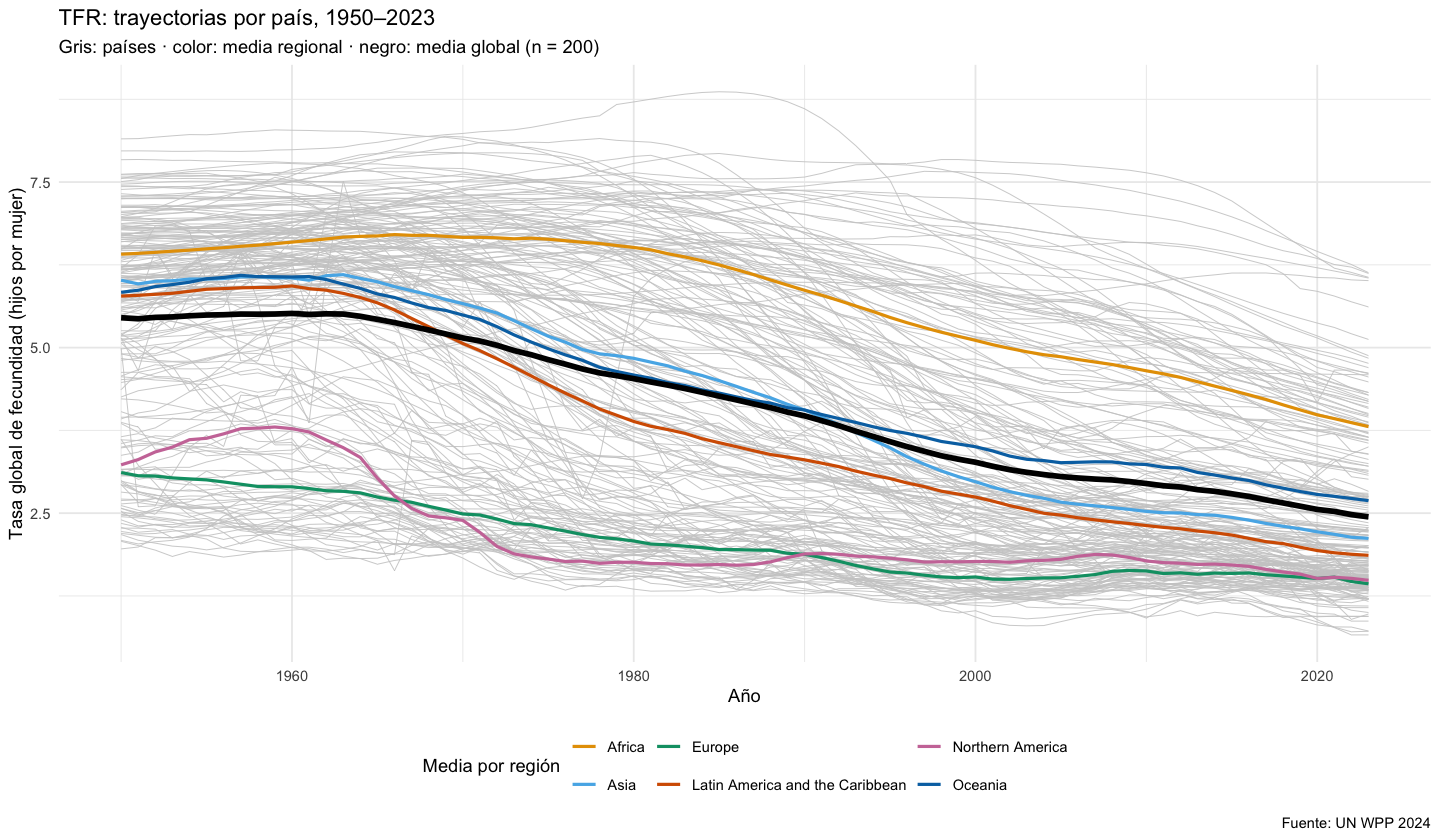

In [3]:
M <- mats[["TFR"]]
p <- fig_spaghetti(M, "TFR")
guardar_fig(p, "eda_TFR_spaghetti"); p


## TFR · 2. Estadísticos funcionales puntuales
Se comparan la media, la media recortada al 10 % y la mediana funcional (la curva con mayor MBD), junto con la banda de cuantiles puntuales 10–90 %. Si la media se separa de la media recortada o de la mediana, hay asimetría o curvas extremas que la arrastran.


Mediana funcional (MBD): Myanmar 
 Time media media_rec mediana_MBD   q10   q90
 1950 5.451     5.580       5.943 2.711 7.131
 1970 5.146     5.226       5.682 2.246 7.264
 1990 3.970     3.878       3.503 1.708 6.520
 2010 2.947     2.765       2.335 1.475 5.295
 2023 2.444     2.296       2.115 1.297 4.224


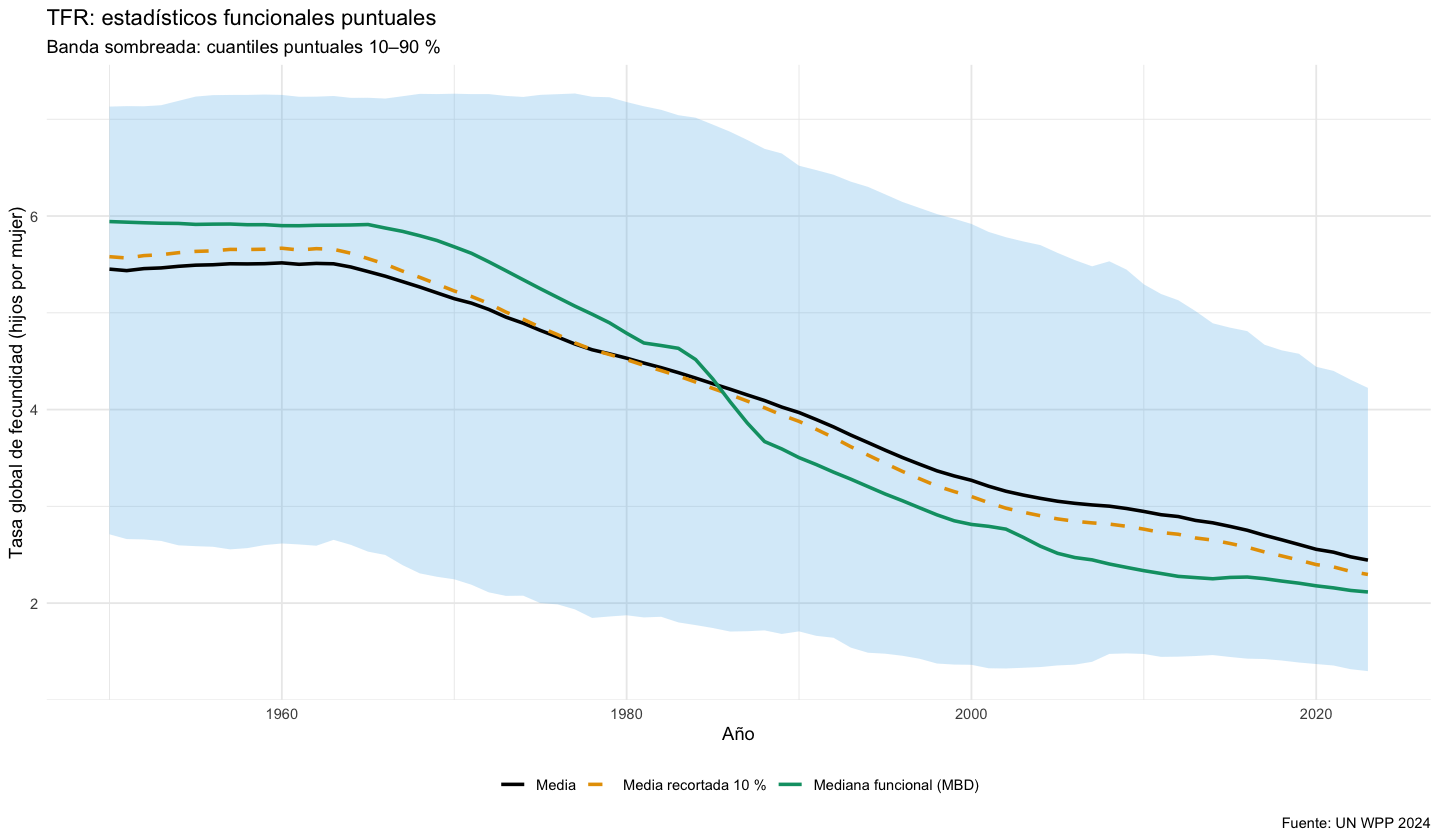

In [4]:
est <- estadisticos(M)
mediana_pais <- meta$Location[which.max(MBD(fData(ANIOS, M)))]
cat("Mediana funcional (MBD):", mediana_pais, "\n")
est |> filter(Time %in% c(1950, 1970, 1990, 2010, 2023)) |>
  select(Time, media, media_rec, mediana_MBD, q10, q90) |> mutate(across(-Time, ~ round(.x, 3))) |>
  as.data.frame() |> print(row.names = FALSE)
p <- fig_estadisticos(est, "TFR")
guardar_fig(p, "eda_TFR_estadisticos"); p


## TFR · 3. Dispersión entre países: $\hat v(t)$ y CV(t)


 Time  media      v     cv
 1950 5.4513 2.5982 0.2957
 1960 5.5161 2.9351 0.3106
 1970 5.1460 3.6155 0.3695
 1980 4.5312 4.2239 0.4536
 1990 3.9695 3.5643 0.4756
 2000 3.2690 3.0356 0.5330
 2010 2.9473 2.3231 0.5171
 2020 2.5561 1.6517 0.5028
 2023 2.4445 1.5293 0.5059


v máx: 4.2348 en 1978 | v mín: 1.5293 en 2023


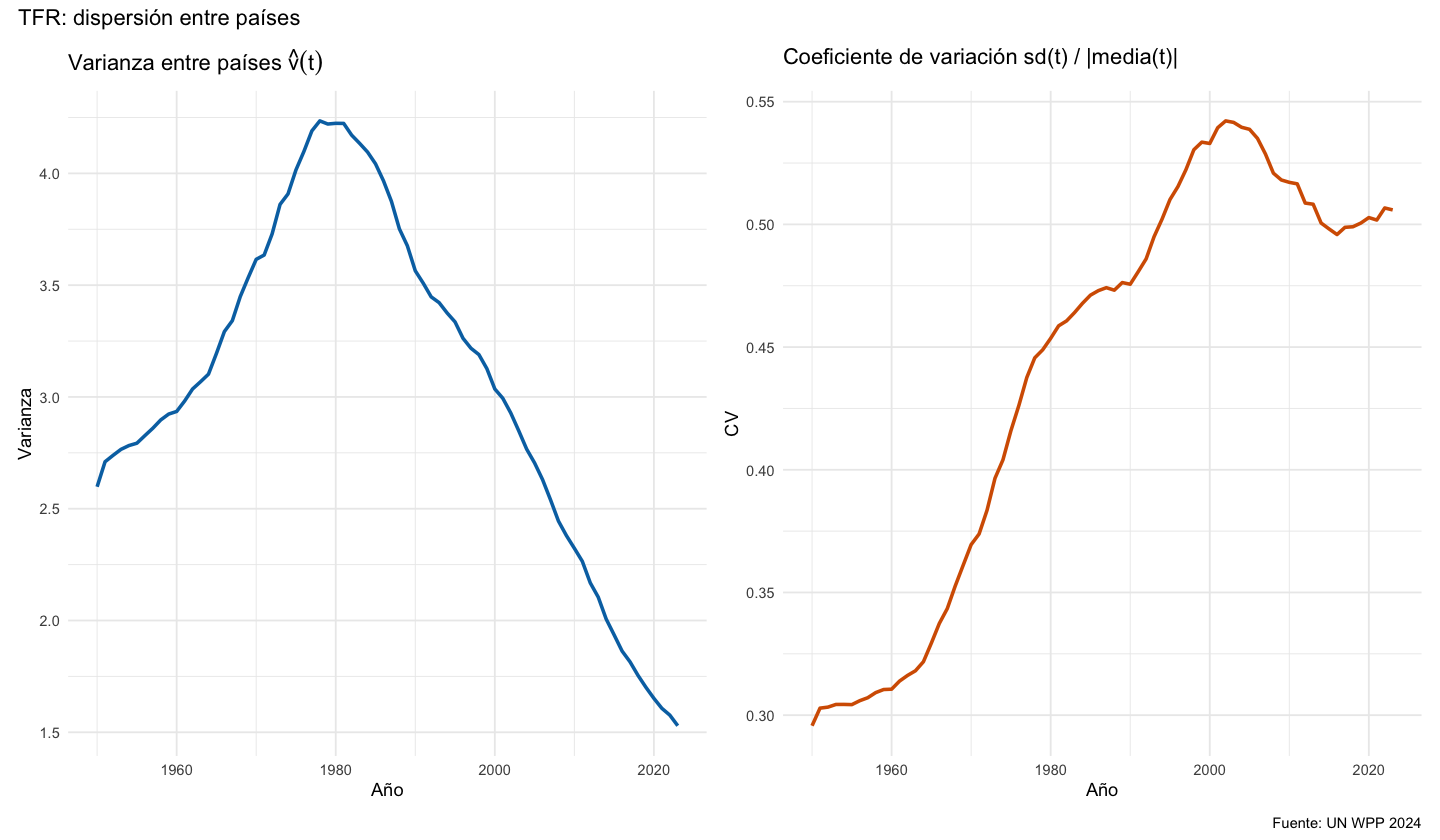

In [5]:
est |> filter(Time %in% c(1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023)) |>
  select(Time, media, v, cv) |> mutate(across(-Time, ~ round(.x, 4))) |>
  as.data.frame() |> print(row.names = FALSE)
cat(sprintf("v máx: %.4f en %d | v mín: %.4f en %d\n", max(est$v), est$Time[which.max(est$v)],
            min(est$v), est$Time[which.min(est$v)]))
p <- fig_varianza(est, "TFR")
guardar_fig(p, "eda_TFR_varianza", w = 11, h = 5); p


**Interpretación (TFR).** Hay dos etapas:
- **Divergencia, 1950–1978.** $\hat v(t)$ sube de 2.60 a 4.23 (máximo en 1978). Europa, Norteamérica y parte de Asia y América Latina inician la transición de la fecundidad mientras África se mantiene en 6–7 hijos, y la distribución se abre.
- **Convergencia absoluta, 1978–2023.** $\hat v(t)$ cae hasta 1.53 en 2023, por debajo del nivel de 1950, porque las regiones rezagadas también reducen su fecundidad.

El CV pasa de 0.30 a ~0.54 (máximo hacia 2002) y luego se estabiliza en ~0.50. **En términos relativos no hay convergencia:** la caída de $\hat v$ se debe en buena parte a que baja el nivel medio, y África sigue lejos (3.8 frente a ~1.5 en Europa). La media global queda por encima de la mediana MBD desde ~1985, lo que indica una cola superior larga formada por los países de alta fecundidad.


## TFR · 4. Atípicos: boxplot funcional y outliergram
El boxplot funcional detecta **atípicos de magnitud** (curvas que salen de las vallas) y el outliergram detecta **atípicos de forma** (curvas muy por debajo de la cota parabólica MBD–MEI). La tabla se guarda en `output/tables/outliers_TFR.csv`.


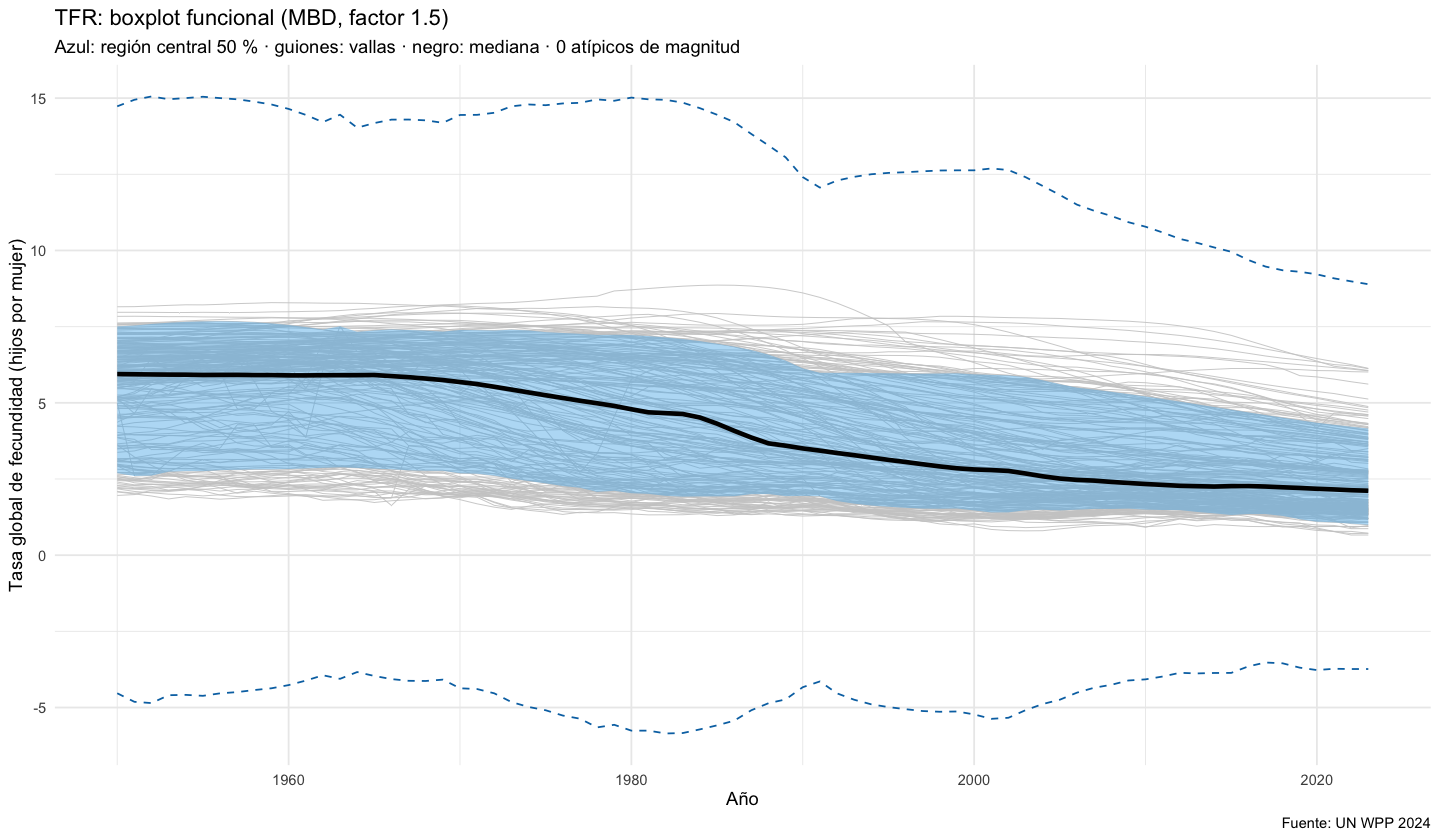

Atípicos de magnitud: 0 | de forma: 14 | en ambos: 0
 indicador  tipo ISO3_code                         Location                          region
       TFR forma       CMR                         Cameroon                          Africa
       TFR forma       CAF         Central African Republic                          Africa
       TFR forma       COD Democratic Republic of the Congo                          Africa
       TFR forma       GNQ                Equatorial Guinea                          Africa
       TFR forma       GAB                            Gabon                          Africa
       TFR forma       BRN                Brunei Darussalam                            Asia
       TFR forma       TWN  China, Taiwan Province of China                            Asia
       TFR forma       IRN       Iran (Islamic Republic of)                            Asia
       TFR forma       KWT                           Kuwait                            Asia
       TFR forma       MDV 

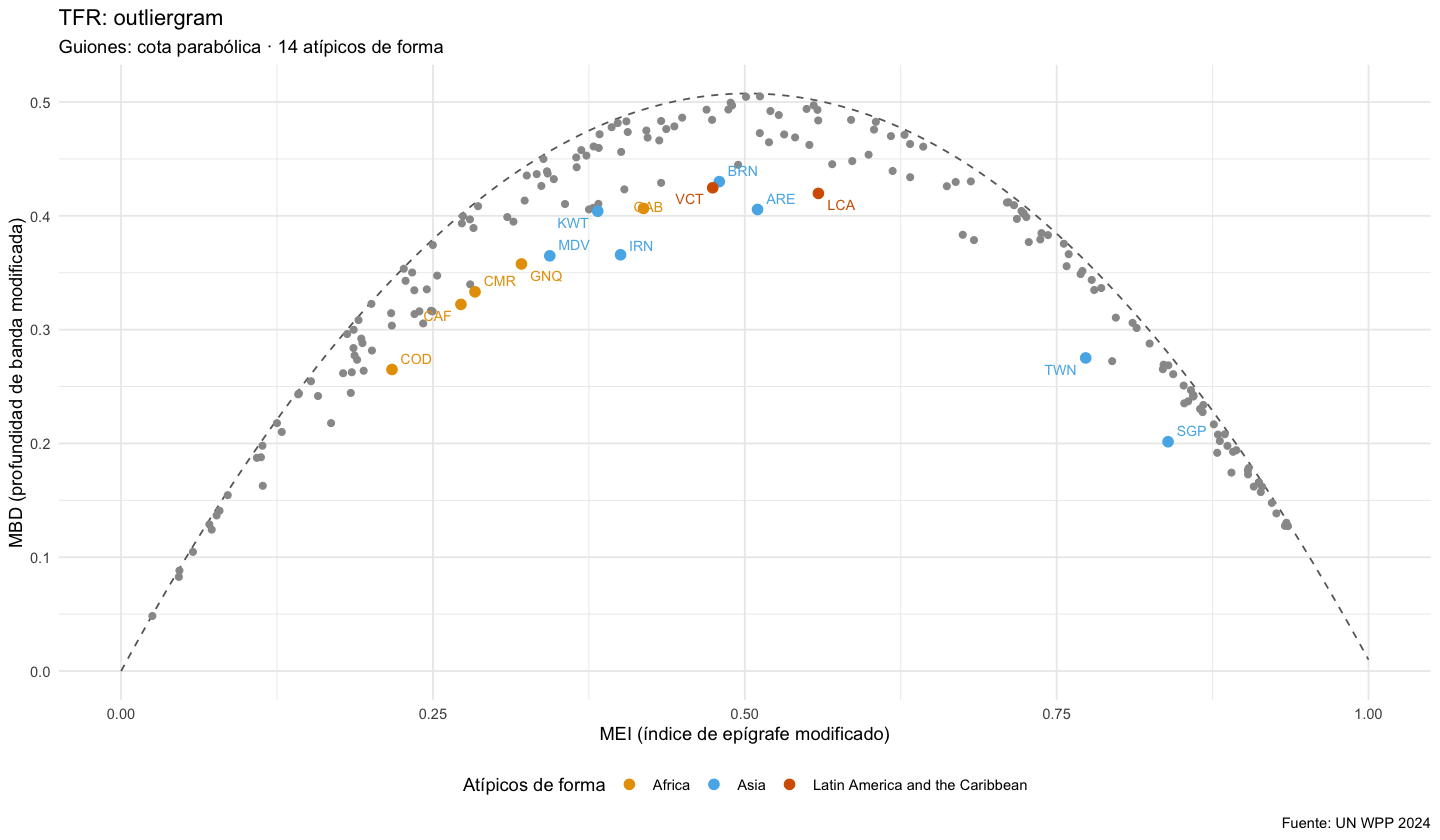

In [6]:
at <- analizar_atipicos(M)
p1 <- fig_fbplot(M, at, "TFR");      guardar_fig(p1, "eda_TFR_fbplot")
p2 <- fig_outliergram(M, at, "TFR"); guardar_fig(p2, "eda_TFR_outliergram")
print(p1); print(p2)

tab_at <- tabla_atipicos(at, "TFR")
guardar_tabla(tab_at, "outliers_TFR")
cat(sprintf("Atípicos de magnitud: %d | de forma: %d | en ambos: %d\n",
            length(at$id_mag), length(at$id_forma), length(intersect(at$id_mag, at$id_forma))))
print(as.data.frame(tab_at), row.names = FALSE)

resumen[["TFR"]] <- tibble(indicador = "TFR",
                              v_1950 = est$v[est$Time == 1950], v_2023 = est$v[est$Time == 2023],
                              n_atip_magnitud = length(at$id_mag), n_atip_forma = length(at$id_forma))


# Indicador: LEx – Esperanza de vida al nacer

## LEx · 1. Trayectorias por país
Cada curva gris es un país. Las líneas de color son las medias por región y la negra gruesa es la media global de los 200 países.


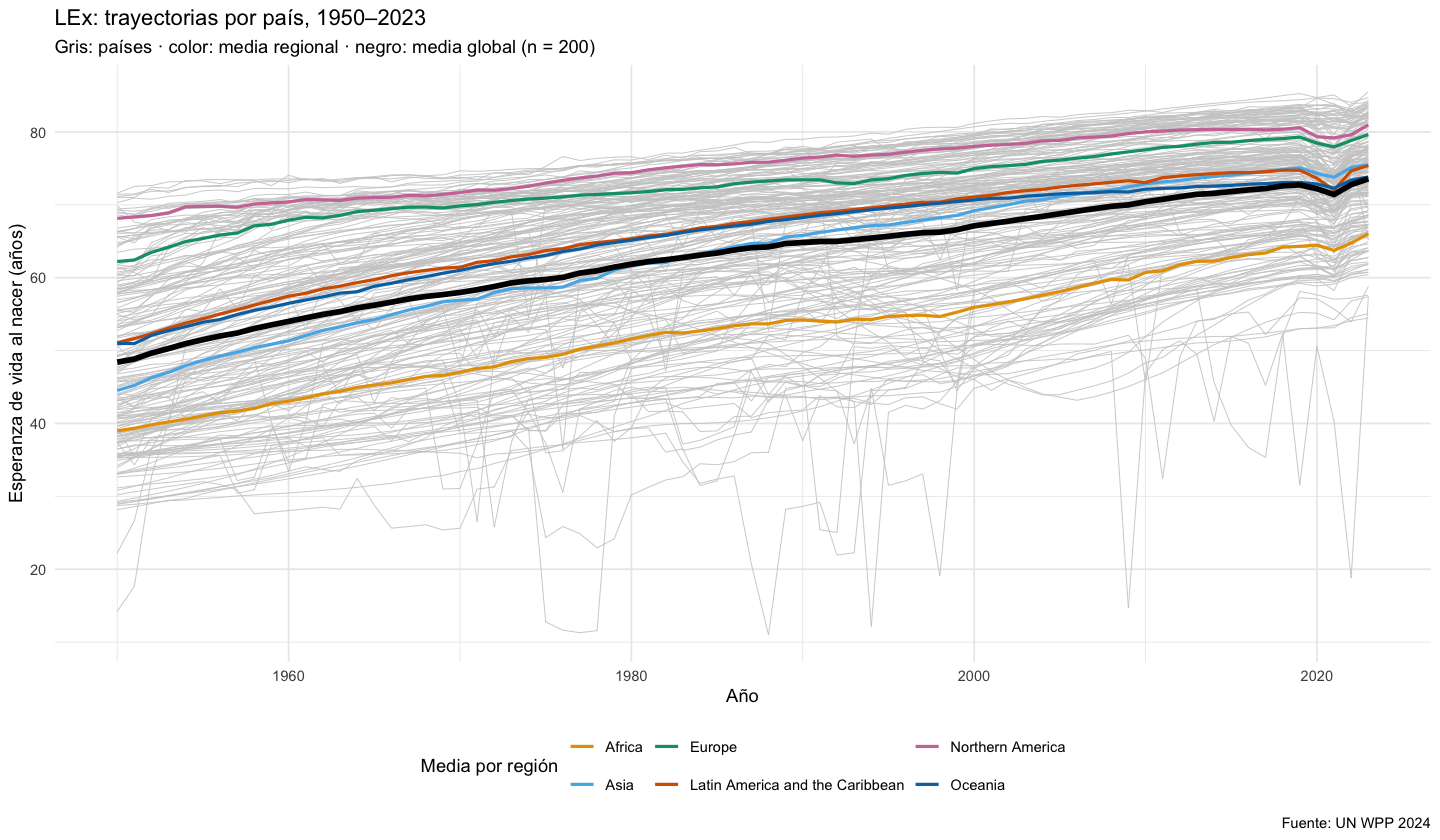

In [7]:
M <- mats[["LEx"]]
p <- fig_spaghetti(M, "LEx")
guardar_fig(p, "eda_LEx_spaghetti"); p


## LEx · 2. Estadísticos funcionales puntuales
Se comparan la media, la media recortada al 10 % y la mediana funcional (la curva con mayor MBD), junto con la banda de cuantiles puntuales 10–90 %. Si la media se separa de la media recortada o de la mediana, hay asimetría o curvas extremas que la arrastran.


Mediana funcional (MBD): Dominican Republic 
 Time  media media_rec mediana_MBD    q10    q90
 1950 48.414    48.167      44.065 35.300 65.592
 1970 57.974    58.714      58.493 41.365 70.953
 1990 64.831    65.886      67.746 48.505 75.876
 2010 70.425    71.191      72.039 57.087 80.728
 2023 73.567    73.959      73.720 63.651 82.408


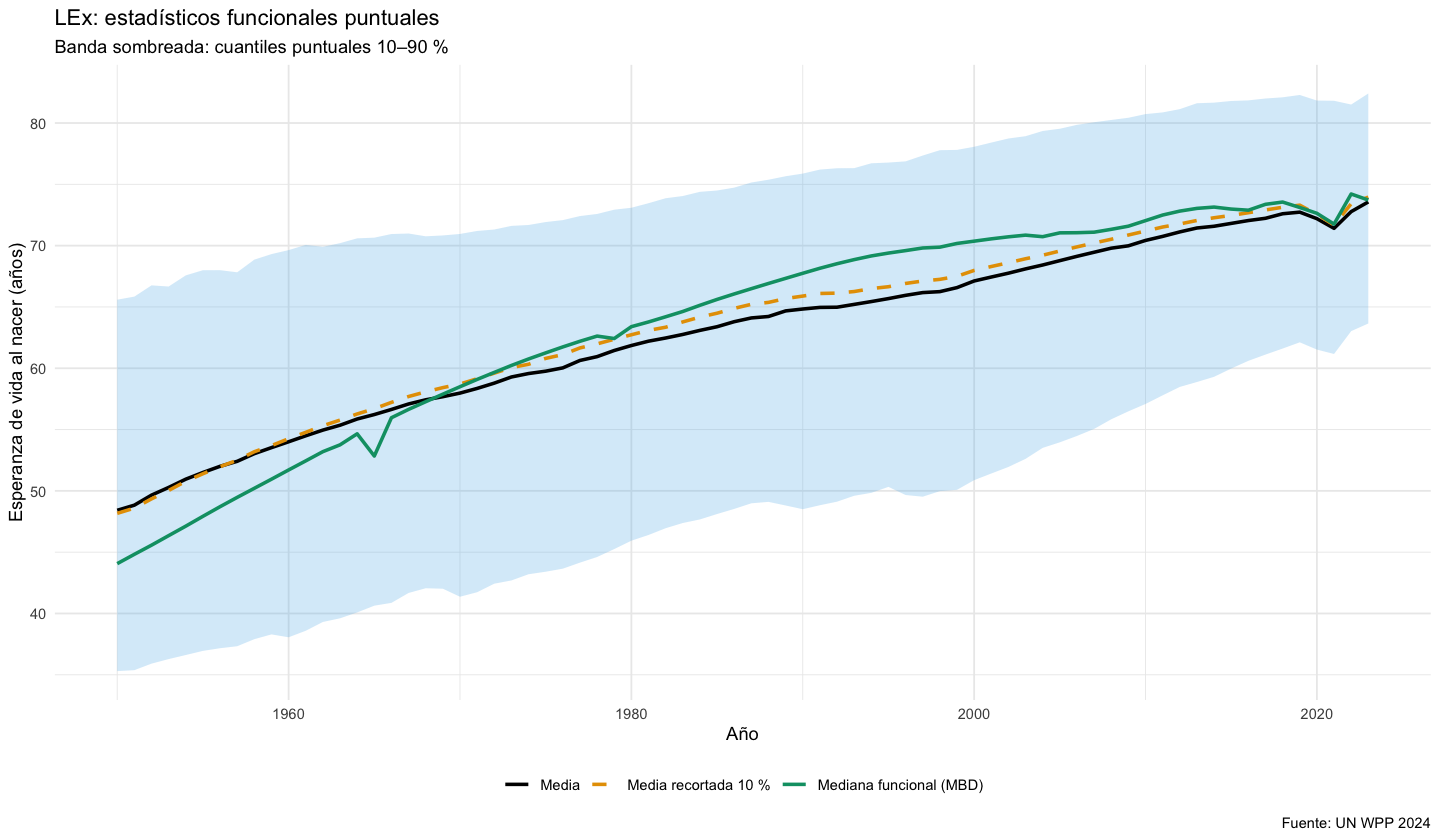

In [8]:
est <- estadisticos(M)
mediana_pais <- meta$Location[which.max(MBD(fData(ANIOS, M)))]
cat("Mediana funcional (MBD):", mediana_pais, "\n")
est |> filter(Time %in% c(1950, 1970, 1990, 2010, 2023)) |>
  select(Time, media, media_rec, mediana_MBD, q10, q90) |> mutate(across(-Time, ~ round(.x, 3))) |>
  as.data.frame() |> print(row.names = FALSE)
p <- fig_estadisticos(est, "LEx")
guardar_fig(p, "eda_LEx_estadisticos"); p


## LEx · 3. Dispersión entre países: $\hat v(t)$ y CV(t)


 Time   media        v     cv
 1950 48.4141 136.9182 0.2417
 1960 54.0031 136.5313 0.2164
 1970 57.9736 123.0632 0.1914
 1980 61.8539 105.4293 0.1660
 1990 64.8309 100.7437 0.1548
 2000 67.1176  94.5832 0.1449
 2010 70.4245  78.2626 0.1256
 2020 72.1996  54.8526 0.1026
 2023 73.5666  50.1962 0.0963
v máx: 136.9182 en 1950 | v mín: 50.1962 en 2023


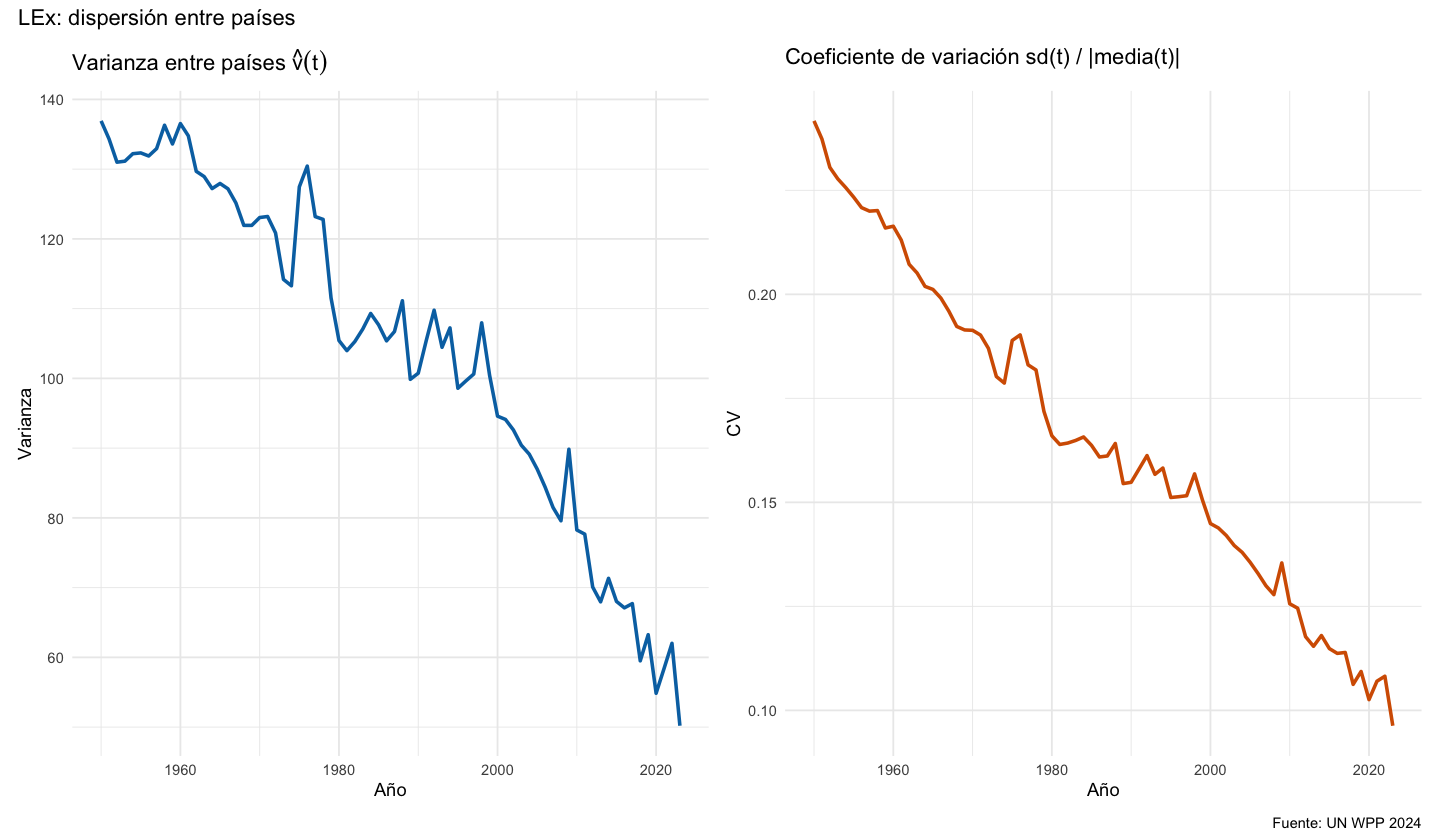

In [9]:
est |> filter(Time %in% c(1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023)) |>
  select(Time, media, v, cv) |> mutate(across(-Time, ~ round(.x, 4))) |>
  as.data.frame() |> print(row.names = FALSE)
cat(sprintf("v máx: %.4f en %d | v mín: %.4f en %d\n", max(est$v), est$Time[which.max(est$v)],
            min(est$v), est$Time[which.min(est$v)]))
p <- fig_varianza(est, "LEx")
guardar_fig(p, "eda_LEx_varianza", w = 11, h = 5); p


**Interpretación (LEx).** Hay **convergencia sostenida**, tanto absoluta como relativa:
- $\hat v(t)$ cae de 136.9 en 1950 (su máximo) a 50.2 en 2023, es decir, un 63 % menos.
- El CV baja de 0.24 a 0.10.
- La brecha entre regiones se cierra porque Asia y América Latina alcanzan a Europa. África sigue siendo la región rezagada (~66 años frente a ~80 en Europa y Northern America en 2023).

La tendencia tiene saltos puntuales de varianza causados por crisis de mortalidad en un solo país: Camboya 1975–78 (mínimo 11.6 en 1976), Sudán del Sur 1988 (11.0), Ruanda 1994 (12.2) y la República Centroafricana 2009 y 2022 (14.7 y 18.8). Son caídas reales pero muy breves, que la reconstrucción con pocas componentes del FPCA (F4) tenderá a suavizar.

El COVID-19 deja una caída común en 2020–2021 en la media de todas las regiones, pero apenas mueve $\hat v(t)$, porque afectó a casi todos los países a la vez.


## LEx · 4. Atípicos: boxplot funcional y outliergram
El boxplot funcional detecta **atípicos de magnitud** (curvas que salen de las vallas) y el outliergram detecta **atípicos de forma** (curvas muy por debajo de la cota parabólica MBD–MEI). La tabla se guarda en `output/tables/outliers_LEx.csv`.


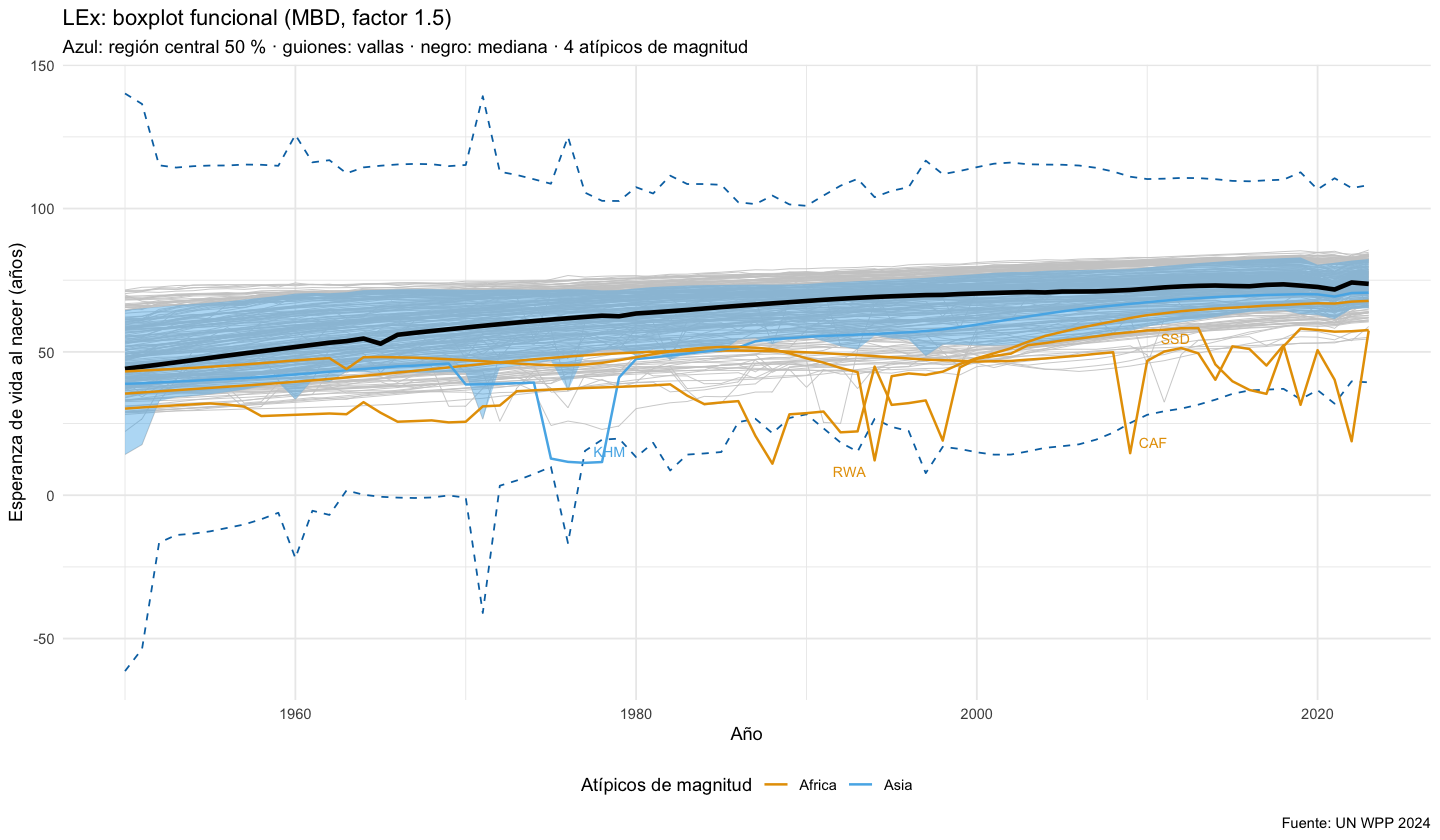

Atípicos de magnitud: 4 | de forma: 17 | en ambos: 0
 indicador     tipo ISO3_code                   Location region
       LEx    forma       DZA                    Algeria Africa
       LEx    forma       LBY                      Libya Africa
       LEx    forma       TUN                    Tunisia Africa
       LEx    forma       ZWE                   Zimbabwe Africa
       LEx    forma       BHR                    Bahrain   Asia
       LEx    forma       IRN Iran (Islamic Republic of)   Asia
       LEx    forma       LBN                    Lebanon   Asia
       LEx    forma       MDV                   Maldives   Asia
       LEx    forma       OMN                       Oman   Asia
       LEx    forma       KOR          Republic of Korea   Asia
       LEx    forma       SAU               Saudi Arabia   Asia
       LEx    forma       ARE       United Arab Emirates   Asia
       LEx    forma       BLR                    Belarus Europe
       LEx    forma       LVA                     L

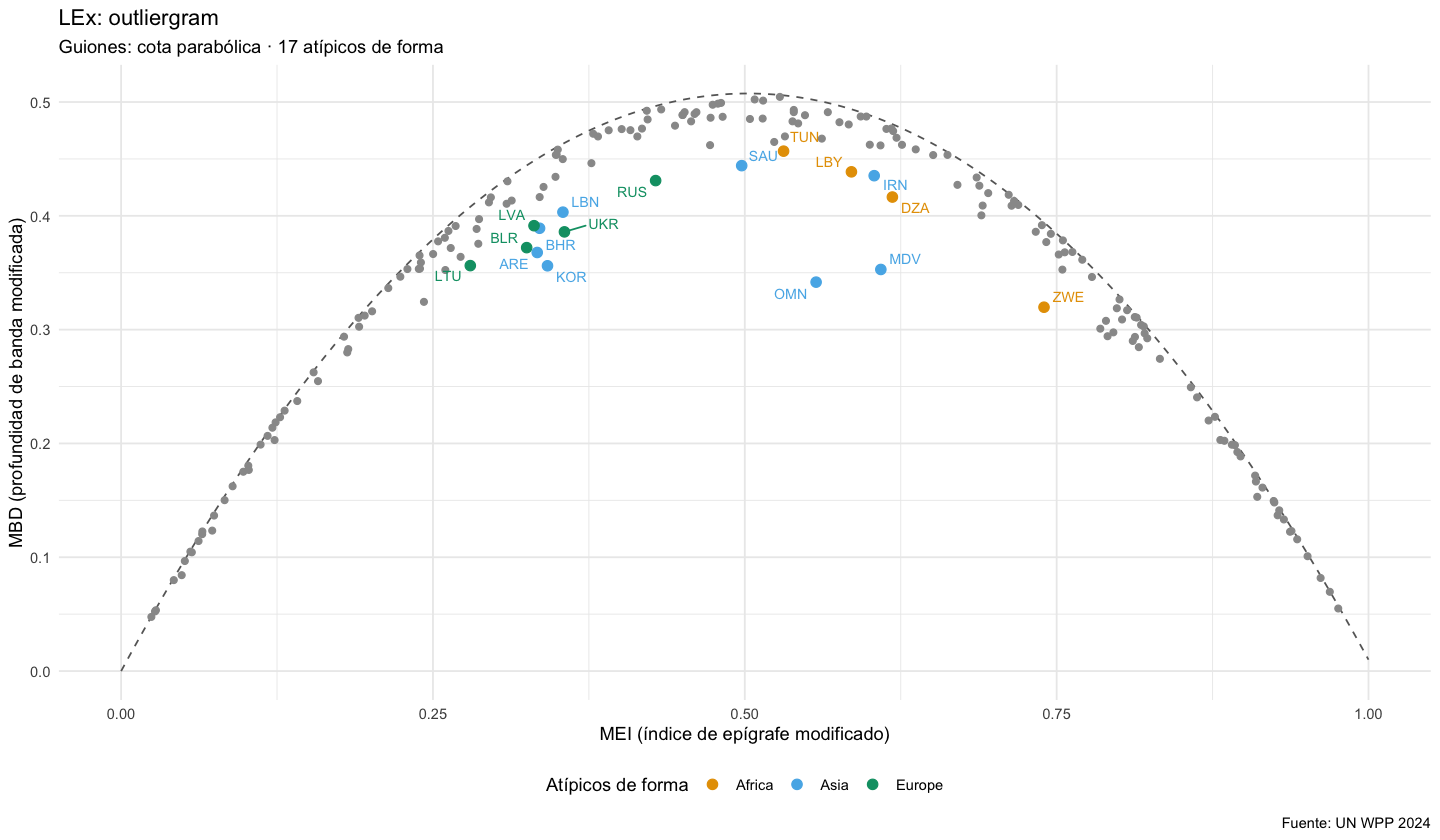

In [10]:
at <- analizar_atipicos(M)
p1 <- fig_fbplot(M, at, "LEx");      guardar_fig(p1, "eda_LEx_fbplot")
p2 <- fig_outliergram(M, at, "LEx"); guardar_fig(p2, "eda_LEx_outliergram")
print(p1); print(p2)

tab_at <- tabla_atipicos(at, "LEx")
guardar_tabla(tab_at, "outliers_LEx")
cat(sprintf("Atípicos de magnitud: %d | de forma: %d | en ambos: %d\n",
            length(at$id_mag), length(at$id_forma), length(intersect(at$id_mag, at$id_forma))))
print(as.data.frame(tab_at), row.names = FALSE)

resumen[["LEx"]] <- tibble(indicador = "LEx",
                              v_1950 = est$v[est$Time == 1950], v_2023 = est$v[est$Time == 2023],
                              n_atip_magnitud = length(at$id_mag), n_atip_forma = length(at$id_forma))


# Indicador: CNMR_t – Tasa neta de migración transformada (asinh)

## CNMR_t · 1. Trayectorias por país
Cada curva gris es un país. Las líneas de color son las medias por región y la negra gruesa es la media global de los 200 países.


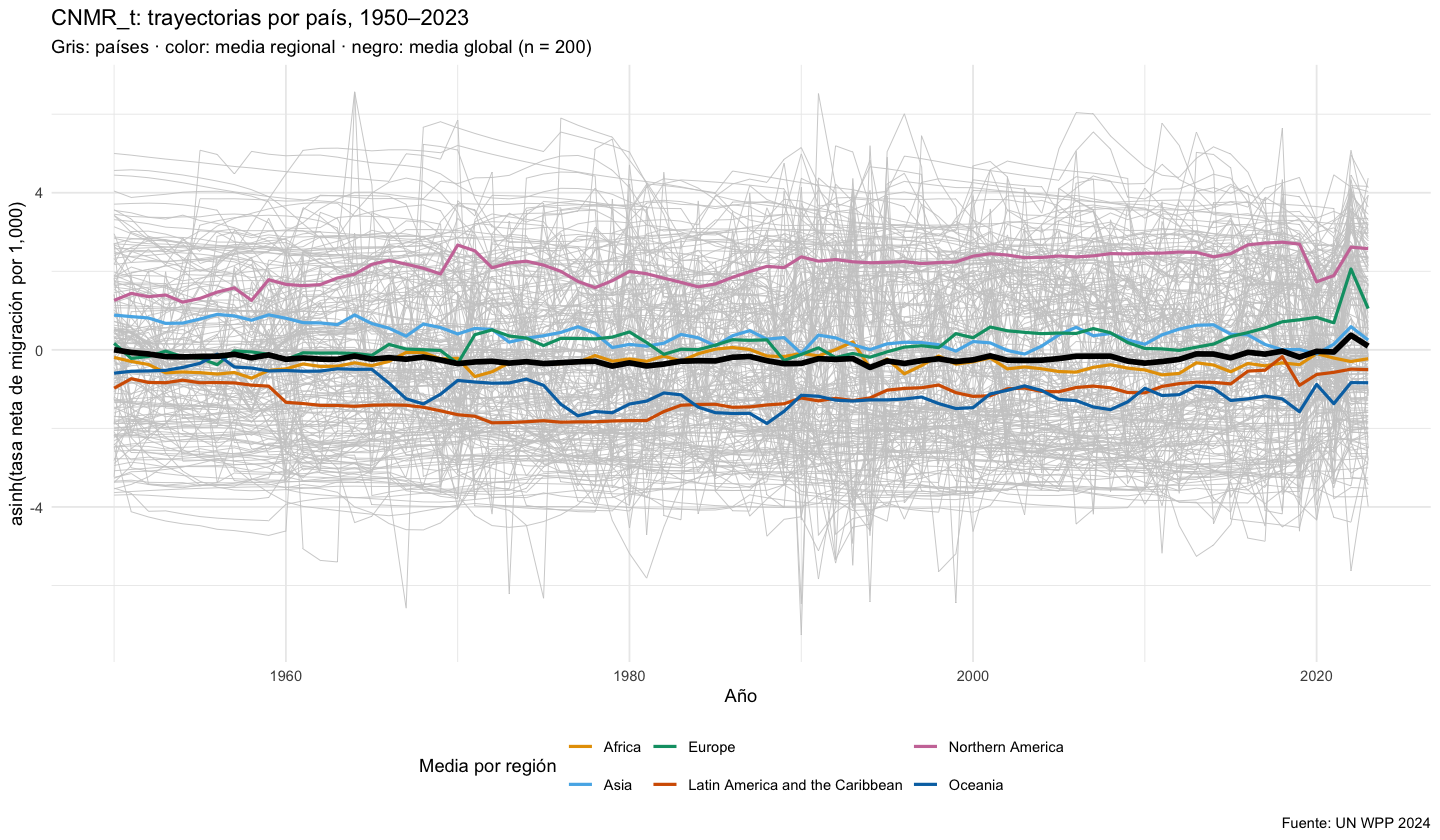

In [11]:
M <- mats[["CNMR_t"]]
p <- fig_spaghetti(M, "CNMR_t")
guardar_fig(p, "eda_CNMR_t_spaghetti"); p


## CNMR_t · 2. Estadísticos funcionales puntuales
Se comparan la media, la media recortada al 10 % y la mediana funcional (la curva con mayor MBD), junto con la banda de cuantiles puntuales 10–90 %. Si la media se separa de la media recortada o de la mediana, hay asimetría o curvas extremas que la arrastran.


Mediana funcional (MBD): Madagascar 
 Time  media media_rec mediana_MBD    q10   q90
 1950  0.002    -0.038       0.000 -2.402 2.580
 1970 -0.351    -0.459      -0.388 -2.950 2.459
 1990 -0.346    -0.398      -0.146 -2.990 2.842
 2010 -0.339    -0.427      -0.089 -2.960 2.710
 2023  0.095     0.054      -0.048 -2.284 2.835


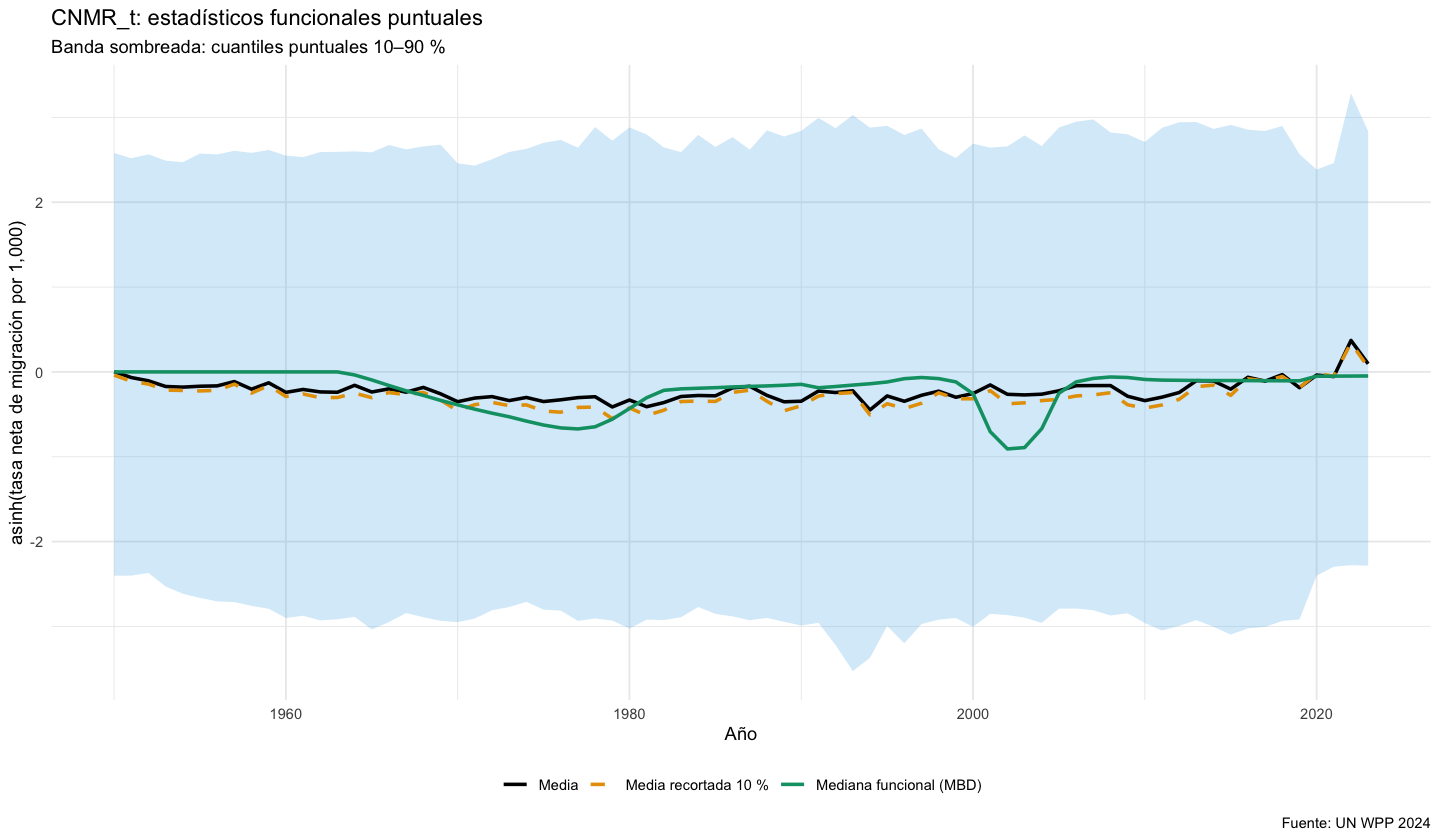

In [12]:
est <- estadisticos(M)
mediana_pais <- meta$Location[which.max(MBD(fData(ANIOS, M)))]
cat("Mediana funcional (MBD):", mediana_pais, "\n")
est |> filter(Time %in% c(1950, 1970, 1990, 2010, 2023)) |>
  select(Time, media, media_rec, mediana_MBD, q10, q90) |> mutate(across(-Time, ~ round(.x, 3))) |>
  as.data.frame() |> print(row.names = FALSE)
p <- fig_estadisticos(est, "CNMR_t")
guardar_fig(p, "eda_CNMR_t_estadisticos"); p


## CNMR_t · 3. Dispersión entre países: $\hat v(t)$ y CV(t)


 Time   media      v       cv
 1950  0.0022 3.3359 819.2214
 1960 -0.2412 4.1906   8.4866
 1970 -0.3511 4.7220   6.1895
 1980 -0.3313 5.2296   6.9026
 1990 -0.3456 5.5330   6.8072
 2000 -0.2550 5.0753   8.8360
 2010 -0.3386 4.5748   6.3164
 2020 -0.0373 3.1064  47.2742
 2023  0.0954 3.6395  19.9914
v máx: 6.0783 en 1993 | v mín: 3.1064 en 2020


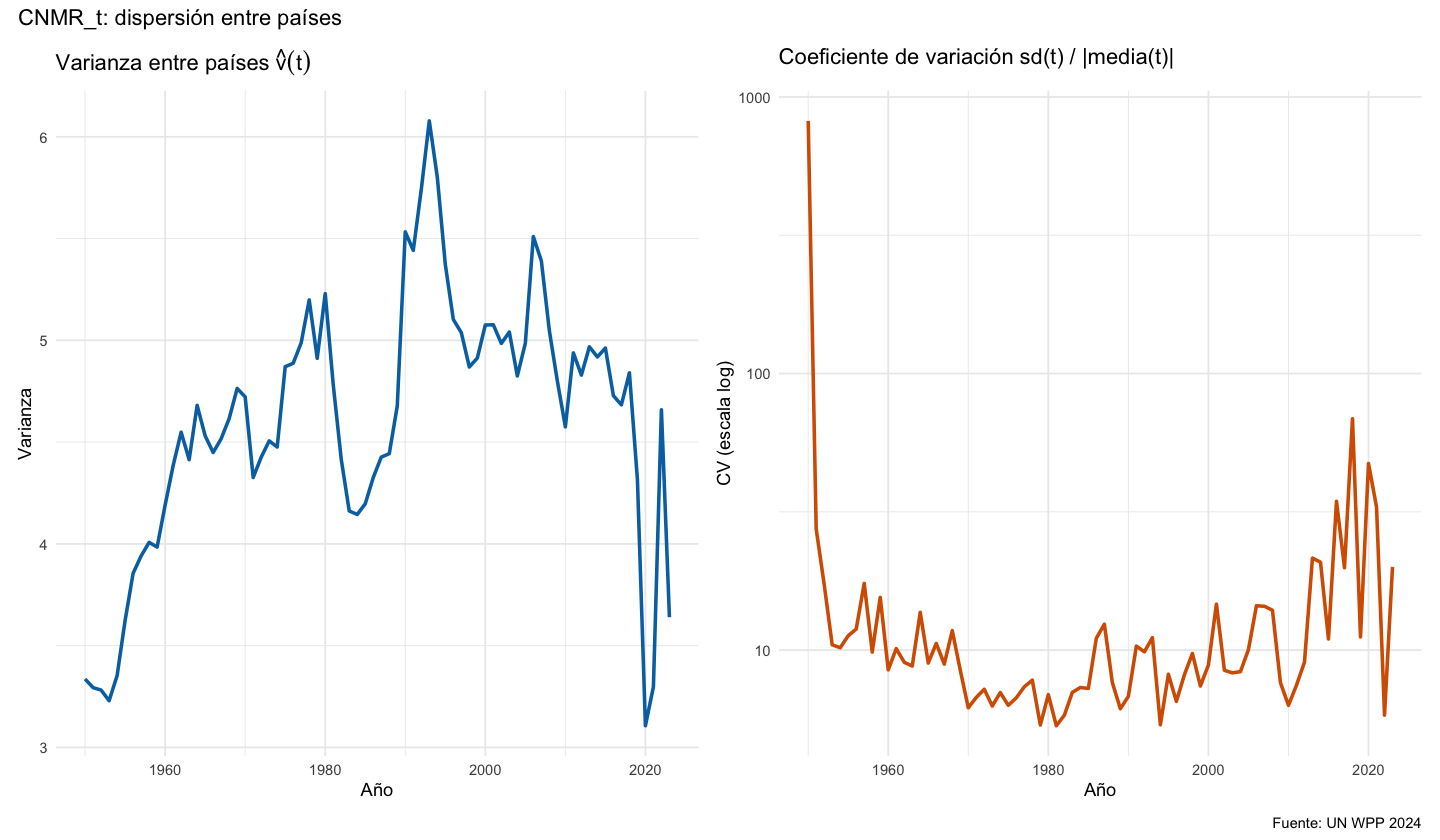

In [13]:
est |> filter(Time %in% c(1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023)) |>
  select(Time, media, v, cv) |> mutate(across(-Time, ~ round(.x, 4))) |>
  as.data.frame() |> print(row.names = FALSE)
cat(sprintf("v máx: %.4f en %d | v mín: %.4f en %d\n", max(est$v), est$Time[which.max(est$v)],
            min(est$v), est$Time[which.min(est$v)]))
p <- fig_varianza(est, "CNMR_t", log_cv = TRUE)  # media ≈ 0: CV no interpretable, escala log
guardar_fig(p, "eda_CNMR_t_varianza", w = 11, h = 5); p


**Interpretación (CNMR_t).** La migración no converge ni diverge de forma monótona. Es la dimensión más ruidosa y con más episodios puntuales:
- **Divergencia moderada, 1950–1993.** $\hat v(t)$ sube de 3.34 a 6.08 (máximo en 1993). Los extremos son episodios concretos: Hong Kong y Macao en 1964 (+357 y +355 ‰), Kuwait y Liberia en 1990 (−710 y −320 ‰; Guerra del Golfo y guerra civil) y Burundi en 1993 (−121 ‰).
- **Meseta con oscilaciones, 1993–2019.** $\hat v(t)$ se mantiene en ~4.5–5.5. Los picos de 2006–2007 vienen de la inmigración laboral al Golfo (Qatar +210 ‰, EAU, Bahréin).
- **Choque de 2020–2022.** $\hat v$ cae a su mínimo en 2020 (3.11), porque con el cierre de fronteras por el COVID-19 la mediana de |CNMR| baja de 2.7 a 1.6 ‰. En 2022 vuelve a subir de golpe por la guerra en Ucrania (−139 ‰), que también explica el salto de la media de Europa.

**El CV no es interpretable aquí:** la media global está cerca de 0 todo el período (en 1950 vale 0.002 y el CV, 819), así que se muestra en escala log solo como referencia. Las medias regionales son estables en signo: Northern America es receptora neta, América Latina y Oceanía son emisoras netas, y Europa pasa de ~0 a receptora desde los años setenta.


## CNMR_t · 4. Atípicos: boxplot funcional y outliergram
El boxplot funcional detecta **atípicos de magnitud** (curvas que salen de las vallas) y el outliergram detecta **atípicos de forma** (curvas muy por debajo de la cota parabólica MBD–MEI). La tabla se guarda en `output/tables/outliers_CNMR_t.csv`.


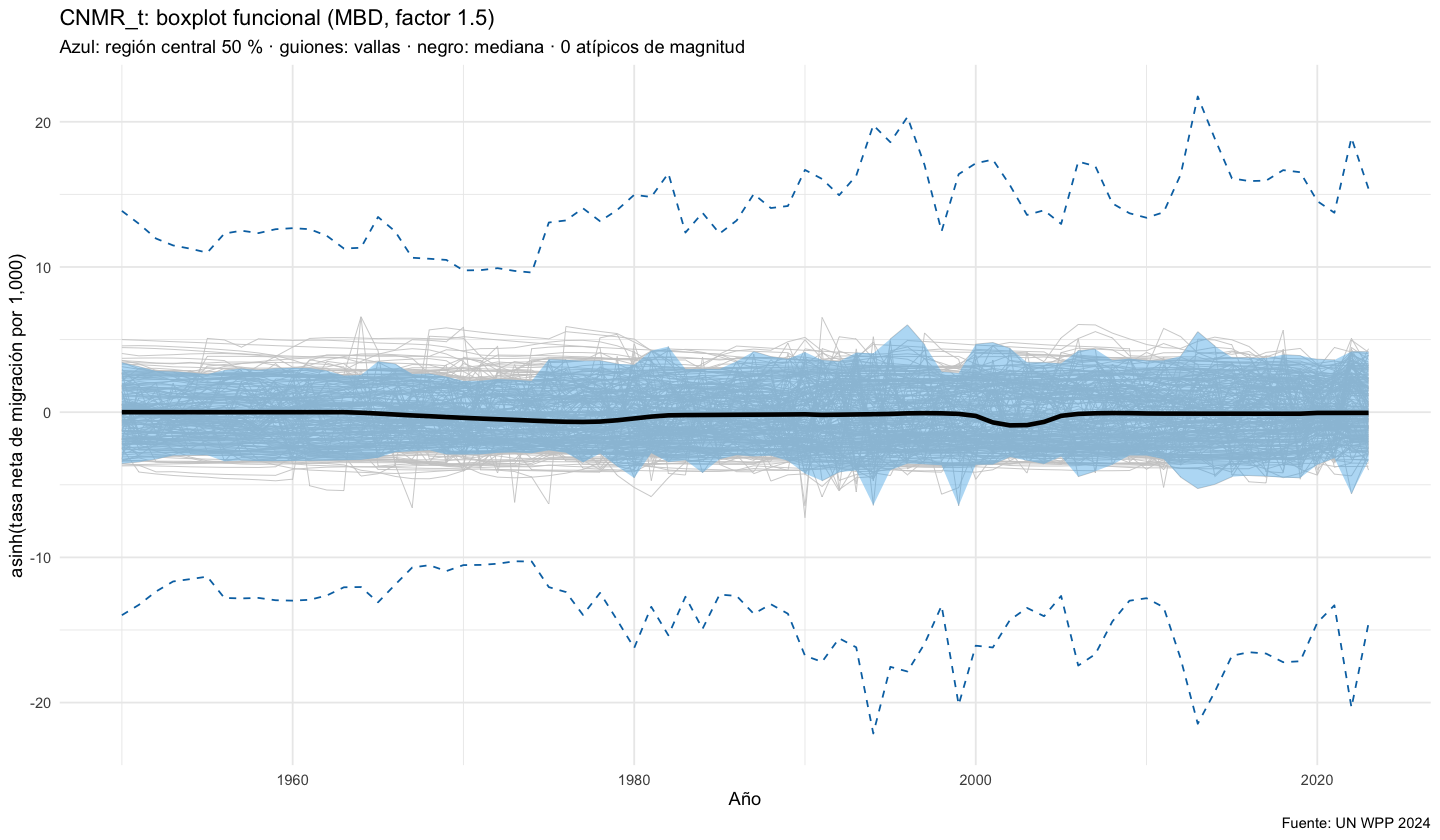

Atípicos de magnitud: 0 | de forma: 1 | en ambos: 0
 indicador  tipo ISO3_code Location region
    CNMR_t forma       ARM  Armenia   Asia


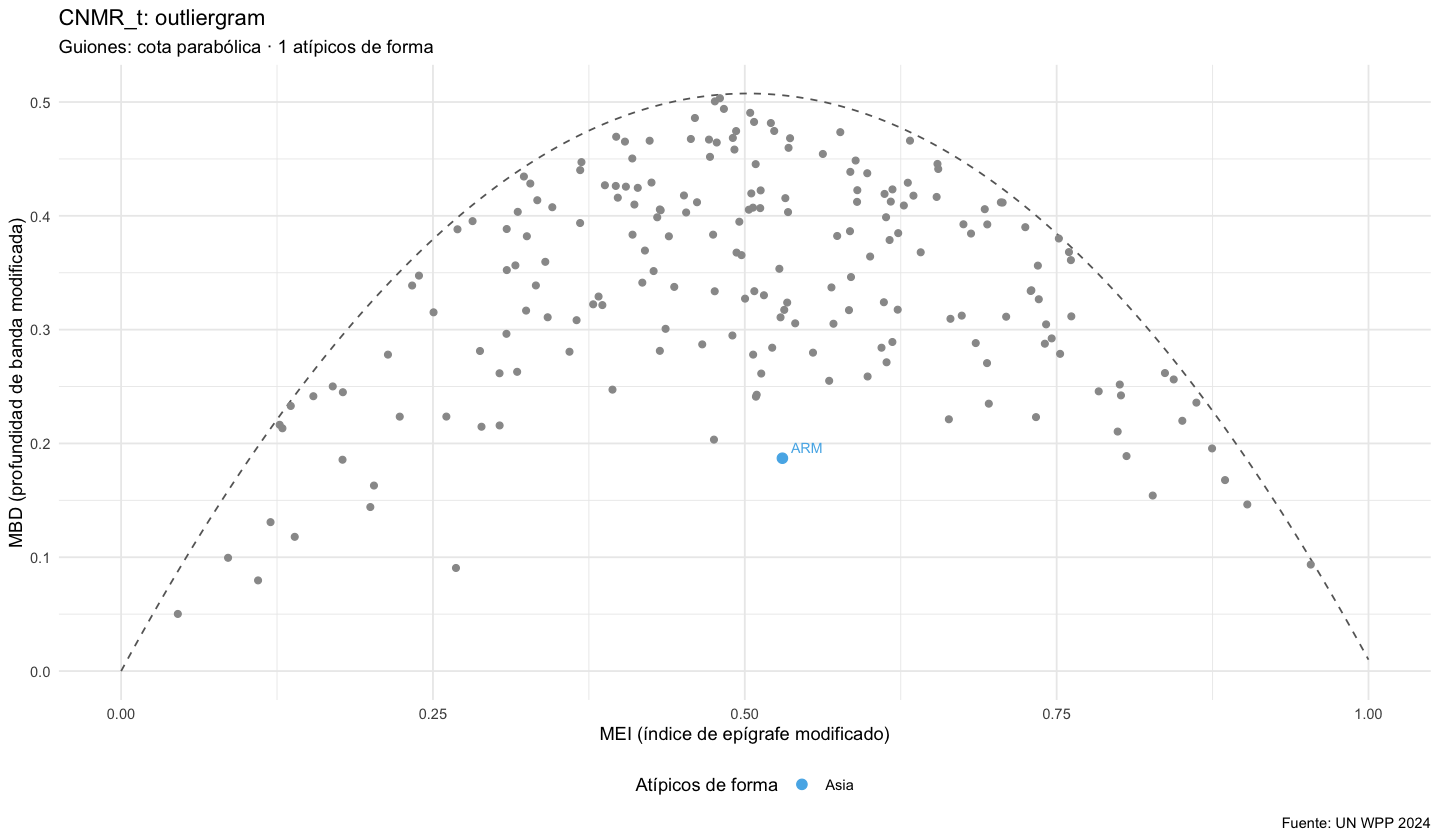

In [14]:
at <- analizar_atipicos(M)
p1 <- fig_fbplot(M, at, "CNMR_t");      guardar_fig(p1, "eda_CNMR_t_fbplot")
p2 <- fig_outliergram(M, at, "CNMR_t"); guardar_fig(p2, "eda_CNMR_t_outliergram")
print(p1); print(p2)

tab_at <- tabla_atipicos(at, "CNMR_t")
guardar_tabla(tab_at, "outliers_CNMR_t")
cat(sprintf("Atípicos de magnitud: %d | de forma: %d | en ambos: %d\n",
            length(at$id_mag), length(at$id_forma), length(intersect(at$id_mag, at$id_forma))))
print(as.data.frame(tab_at), row.names = FALSE)

resumen[["CNMR_t"]] <- tibble(indicador = "CNMR_t",
                              v_1950 = est$v[est$Time == 1950], v_2023 = est$v[est$Time == 2023],
                              n_atip_magnitud = length(at$id_mag), n_atip_forma = length(at$id_forma))


# Indicador: MAC – Edad media a la maternidad

## MAC · 1. Trayectorias por país
Cada curva gris es un país. Las líneas de color son las medias por región y la negra gruesa es la media global de los 200 países.


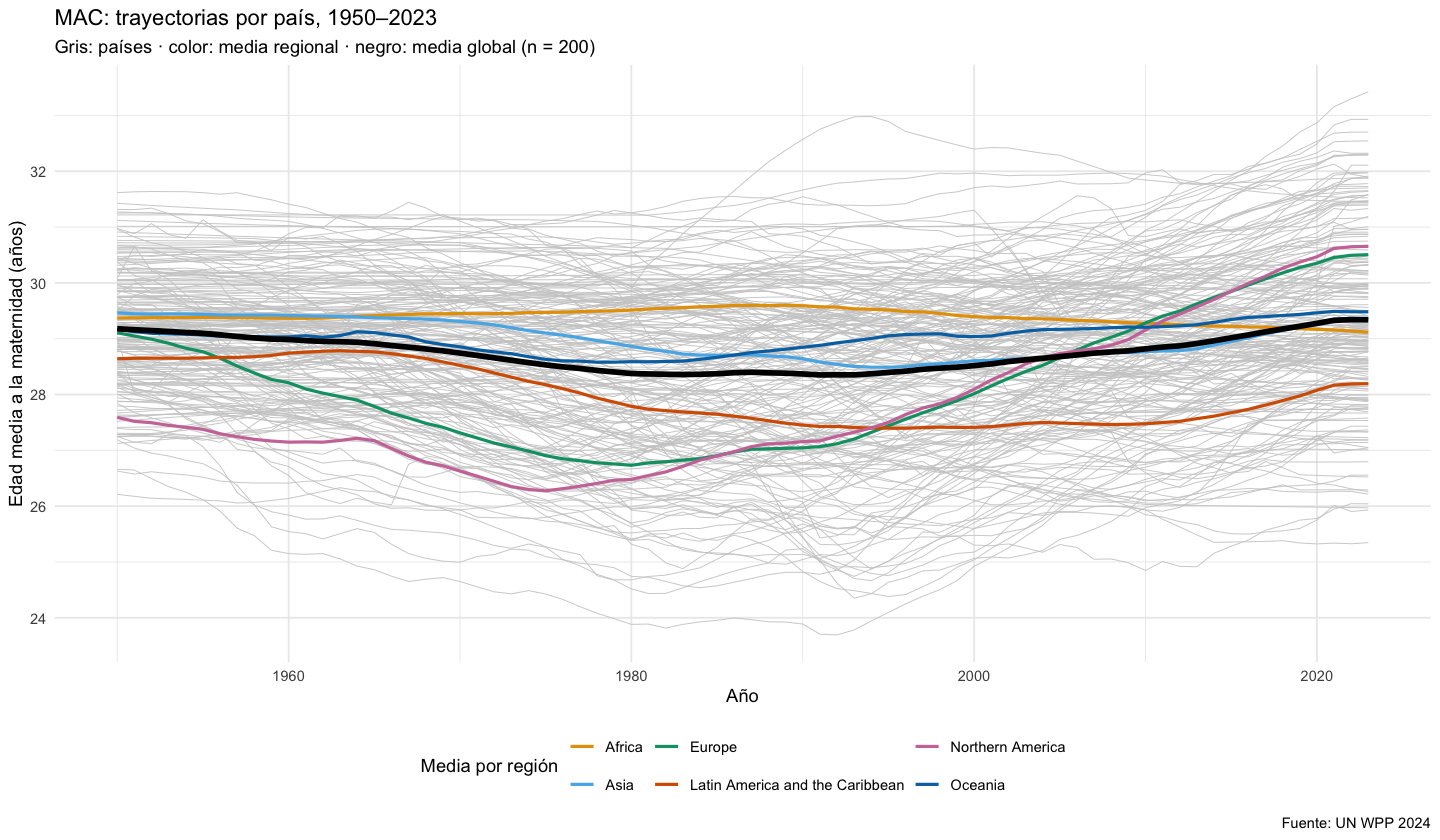

In [15]:
M <- mats[["MAC"]]
p <- fig_spaghetti(M, "MAC")
guardar_fig(p, "eda_MAC_spaghetti"); p


## MAC · 2. Estadísticos funcionales puntuales
Se comparan la media, la media recortada al 10 % y la mediana funcional (la curva con mayor MBD), junto con la banda de cuantiles puntuales 10–90 %. Si la media se separa de la media recortada o de la mediana, hay asimetría o curvas extremas que la arrastran.


Mediana funcional (MBD): Lebanon 
 Time  media media_rec mediana_MBD    q10    q90
 1950 29.178    29.192      28.995 27.834 30.543
 1970 28.742    28.789      28.980 26.941 30.316
 1990 28.369    28.434      28.705 26.045 30.240
 2010 28.819    28.863      29.240 26.787 30.499
 2023 29.338    29.318      29.242 27.426 31.586


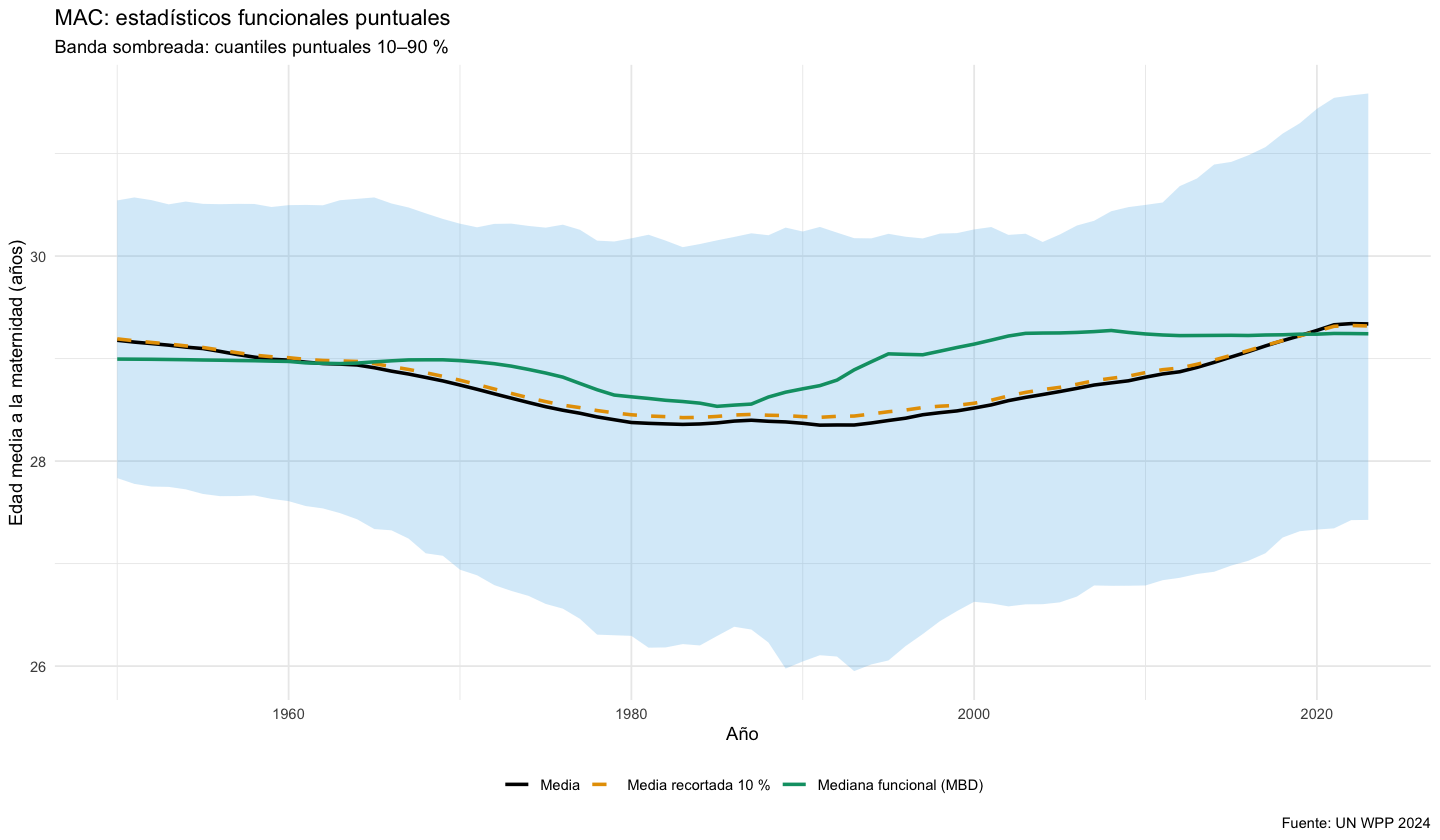

In [16]:
est <- estadisticos(M)
mediana_pais <- meta$Location[which.max(MBD(fData(ANIOS, M)))]
cat("Mediana funcional (MBD):", mediana_pais, "\n")
est |> filter(Time %in% c(1950, 1970, 1990, 2010, 2023)) |>
  select(Time, media, media_rec, mediana_MBD, q10, q90) |> mutate(across(-Time, ~ round(.x, 3))) |>
  as.data.frame() |> print(row.names = FALSE)
p <- fig_estadisticos(est, "MAC")
guardar_fig(p, "eda_MAC_estadisticos"); p


## MAC · 3. Dispersión entre países: $\hat v(t)$ y CV(t)


 Time   media      v     cv
 1950 29.1783 1.1061 0.0360
 1960 28.9850 1.3348 0.0399
 1970 28.7418 1.7308 0.0458
 1980 28.3763 2.3599 0.0541
 1990 28.3687 2.5760 0.0566
 2000 28.5175 2.1996 0.0520
 2010 28.8185 1.9583 0.0486
 2020 29.2745 2.2932 0.0517
 2023 29.3381 2.4731 0.0536
v máx: 2.7098 en 1993 | v mín: 1.1061 en 1950


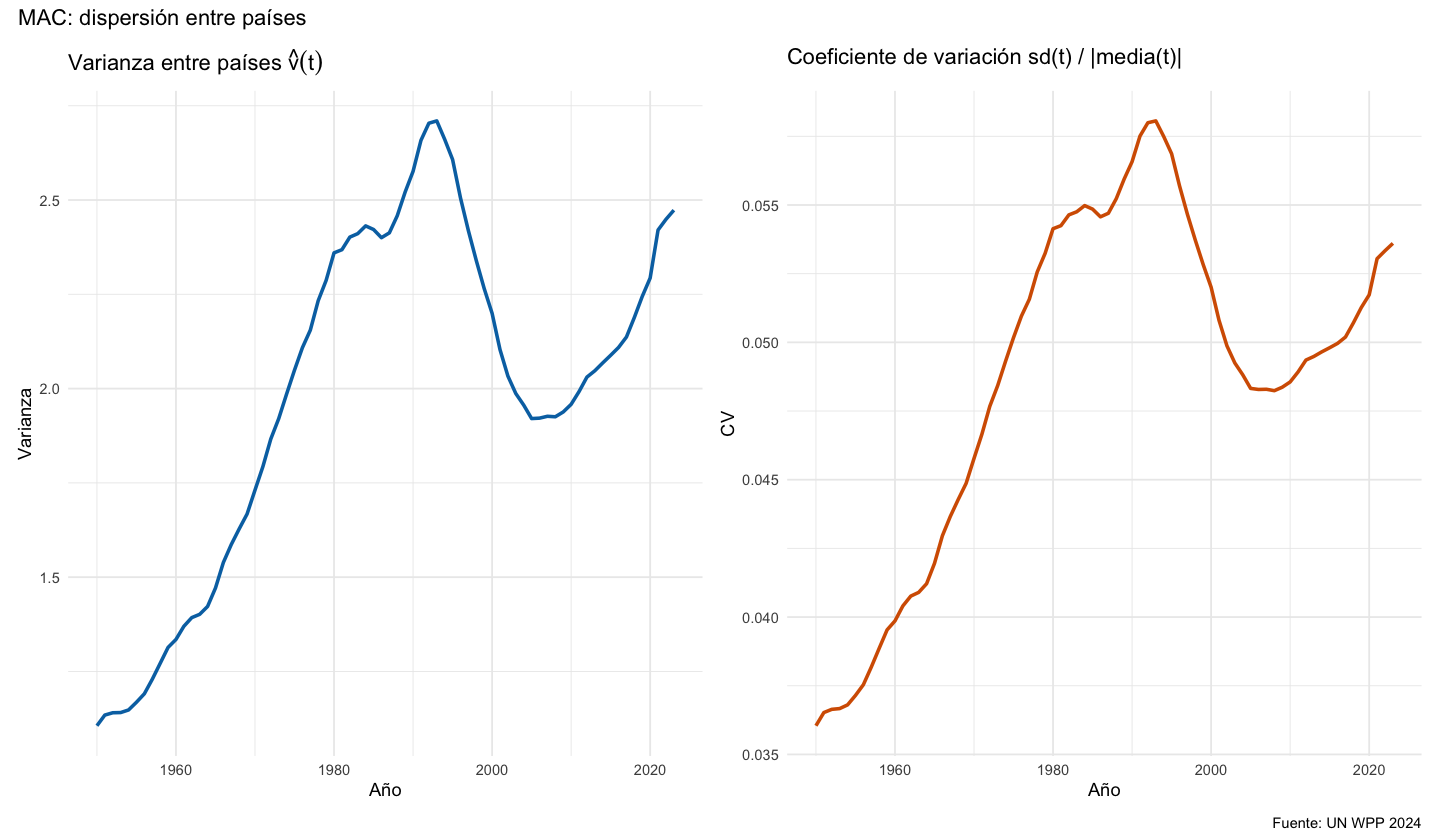

In [17]:
est |> filter(Time %in% c(1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023)) |>
  select(Time, media, v, cv) |> mutate(across(-Time, ~ round(.x, 4))) |>
  as.data.frame() |> print(row.names = FALSE)
cat(sprintf("v máx: %.4f en %d | v mín: %.4f en %d\n", max(est$v), est$Time[which.max(est$v)],
            min(est$v), est$Time[which.min(est$v)]))
p <- fig_varianza(est, "MAC")
guardar_fig(p, "eda_MAC_varianza", w = 11, h = 5); p


**Interpretación (MAC).** La dispersión no sigue una tendencia monótona; la curva tiene forma de **onda** con tres etapas:
- **Divergencia, 1950–1993.** $\hat v(t)$ pasa de 1.11 a 2.71 (máximo en 1993). Al bajar la fecundidad, los nacimientos de orden alto, que ocurren a edades mayores, se vuelven raros, y Europa y Northern America adelantan la maternidad (MAC mínima ~26.5–27 años hacia 1975–1980). África, con fecundidad alta, se mantiene plana en ~29.5 años.
- **Convergencia transitoria, 1993–2006.** $\hat v(t)$ baja a ~1.92. Los países ricos inician el **aplazamiento** de la maternidad y vuelven a pasar por la zona media de la distribución.
- **Nueva divergencia, 2006–2023.** $\hat v(t)$ sube a 2.47, porque el aplazamiento lleva a Europa y Northern America por encima de 30.5 años mientras América Latina sigue en ~28.

El CV sigue la misma onda (0.036 → 0.058 → 0.048 → 0.054), porque la media casi no cambia (28.4–29.3).

**Implicación:** en MAC, lo que distingue a los países es la *forma* de la curva (en U en los países que hicieron la transición, plana en los que no) más que su nivel. Es justo el tipo de información que un corte transversal no captura.


## MAC · 4. Atípicos: boxplot funcional y outliergram
El boxplot funcional detecta **atípicos de magnitud** (curvas que salen de las vallas) y el outliergram detecta **atípicos de forma** (curvas muy por debajo de la cota parabólica MBD–MEI). La tabla se guarda en `output/tables/outliers_MAC.csv`.


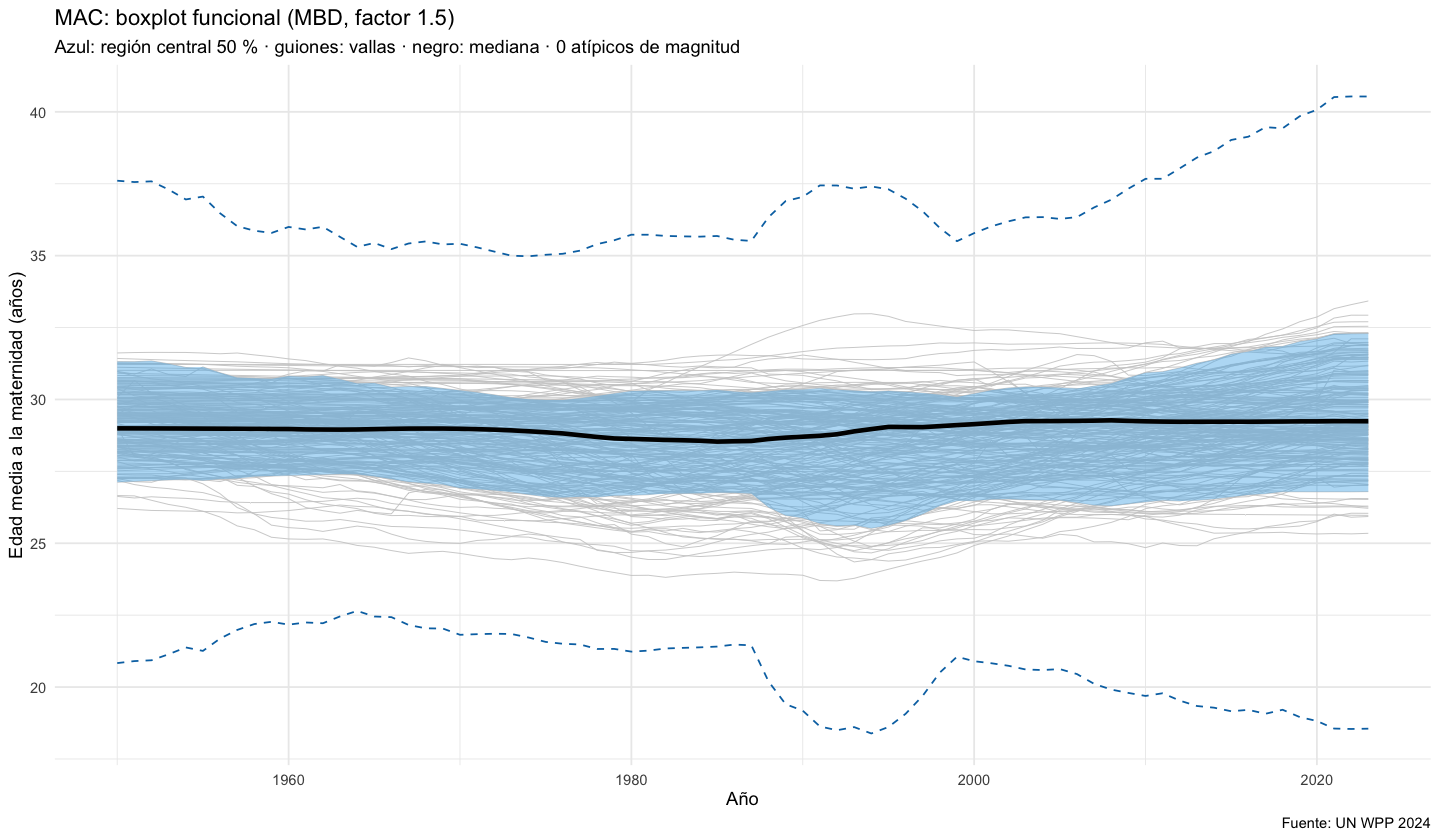

Atípicos de magnitud: 0 | de forma: 5 | en ambos: 0
 indicador  tipo ISO3_code   Location region
       MAC forma       TJK Tajikistan   Asia
       MAC forma       UZB Uzbekistan   Asia
       MAC forma       VNM   Viet Nam   Asia
       MAC forma       DNK    Denmark Europe
       MAC forma       SWE     Sweden Europe


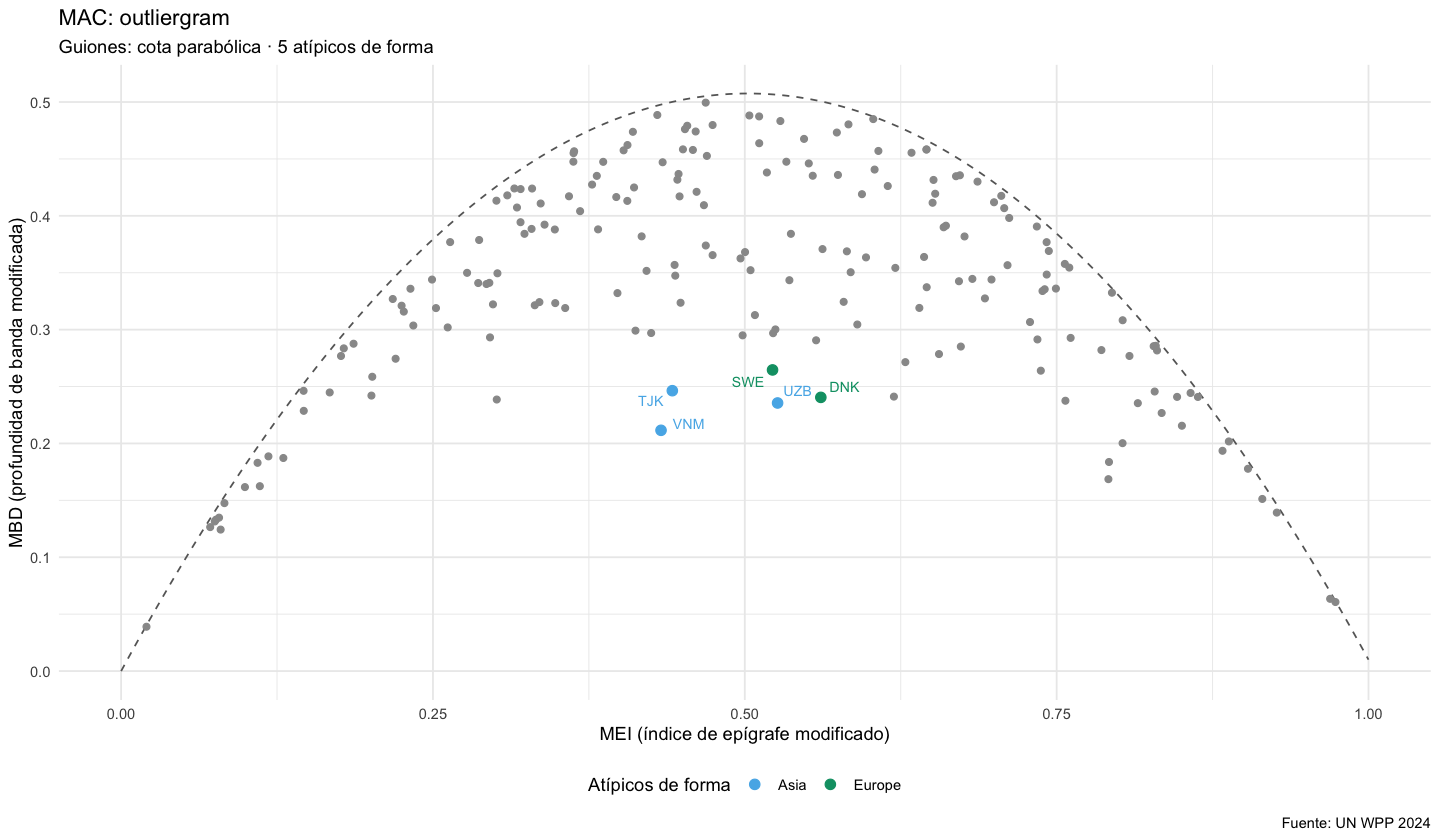

In [18]:
at <- analizar_atipicos(M)
p1 <- fig_fbplot(M, at, "MAC");      guardar_fig(p1, "eda_MAC_fbplot")
p2 <- fig_outliergram(M, at, "MAC"); guardar_fig(p2, "eda_MAC_outliergram")
print(p1); print(p2)

tab_at <- tabla_atipicos(at, "MAC")
guardar_tabla(tab_at, "outliers_MAC")
cat(sprintf("Atípicos de magnitud: %d | de forma: %d | en ambos: %d\n",
            length(at$id_mag), length(at$id_forma), length(intersect(at$id_mag, at$id_forma))))
print(as.data.frame(tab_at), row.names = FALSE)

resumen[["MAC"]] <- tibble(indicador = "MAC",
                              v_1950 = est$v[est$Time == 1950], v_2023 = est$v[est$Time == 2023],
                              n_atip_magnitud = length(at$id_mag), n_atip_forma = length(at$id_forma))


# Indicador: MedianAgePop – Edad mediana de la población

## MedianAgePop · 1. Trayectorias por país
Cada curva gris es un país. Las líneas de color son las medias por región y la negra gruesa es la media global de los 200 países.


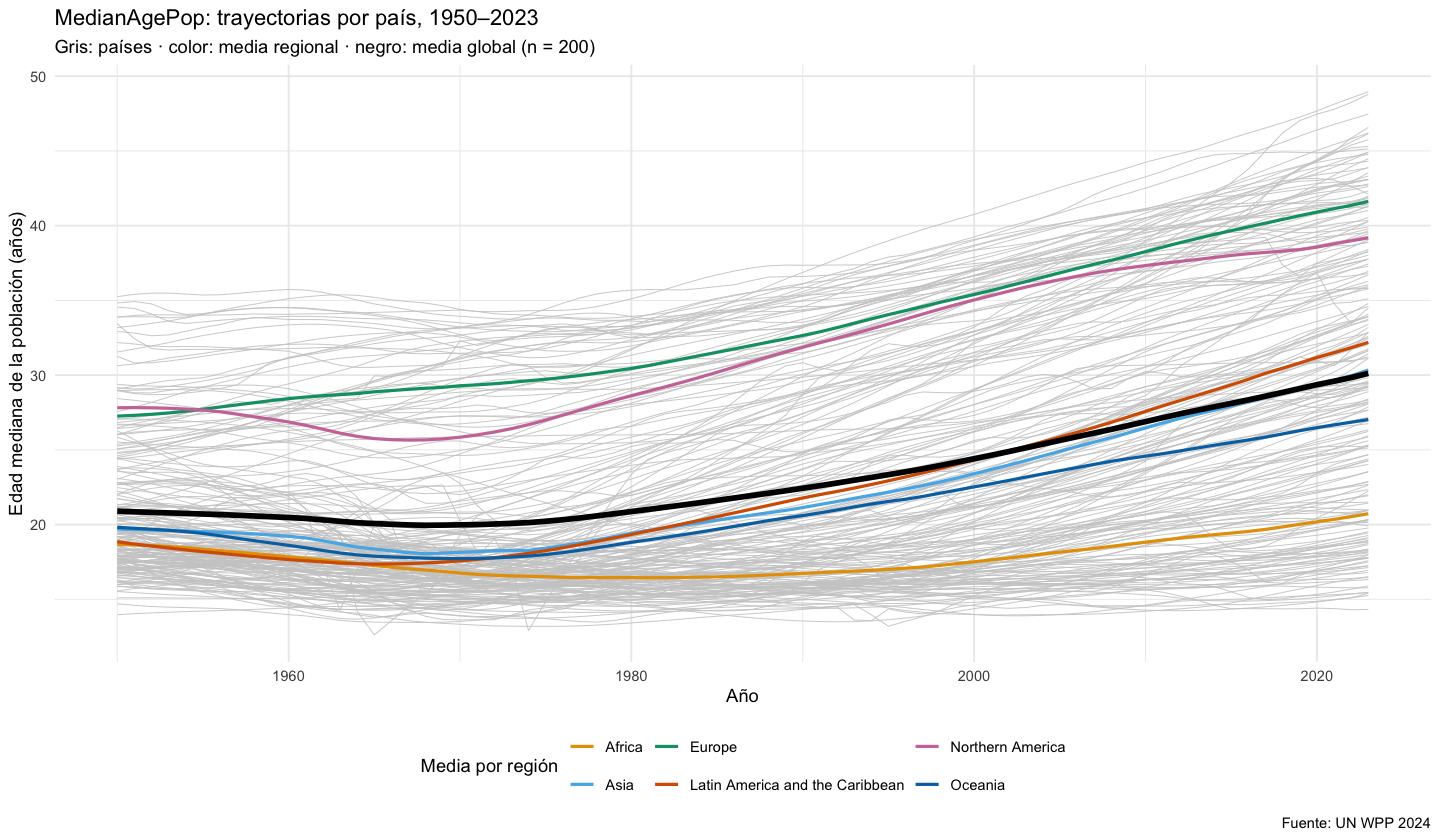

In [19]:
M <- mats[["MedianAgePop"]]
p <- fig_spaghetti(M, "MedianAgePop")
guardar_fig(p, "eda_MedianAgePop_spaghetti"); p


## MedianAgePop · 2. Estadísticos funcionales puntuales
Se comparan la media, la media recortada al 10 % y la mediana funcional (la curva con mayor MBD), junto con la banda de cuantiles puntuales 10–90 %. Si la media se separa de la media recortada o de la mediana, hay asimetría o curvas extremas que la arrastran.


Mediana funcional (MBD): South Africa 
 Time  media media_rec mediana_MBD    q10    q90
 1950 20.896    20.205      19.206 16.691 27.120
 1970 19.979    19.102      17.709 15.113 30.915
 1990 22.429    21.744      20.256 15.522 33.552
 2010 26.888    26.567      23.641 16.581 39.286
 2023 30.118    29.928      28.213 17.805 43.079


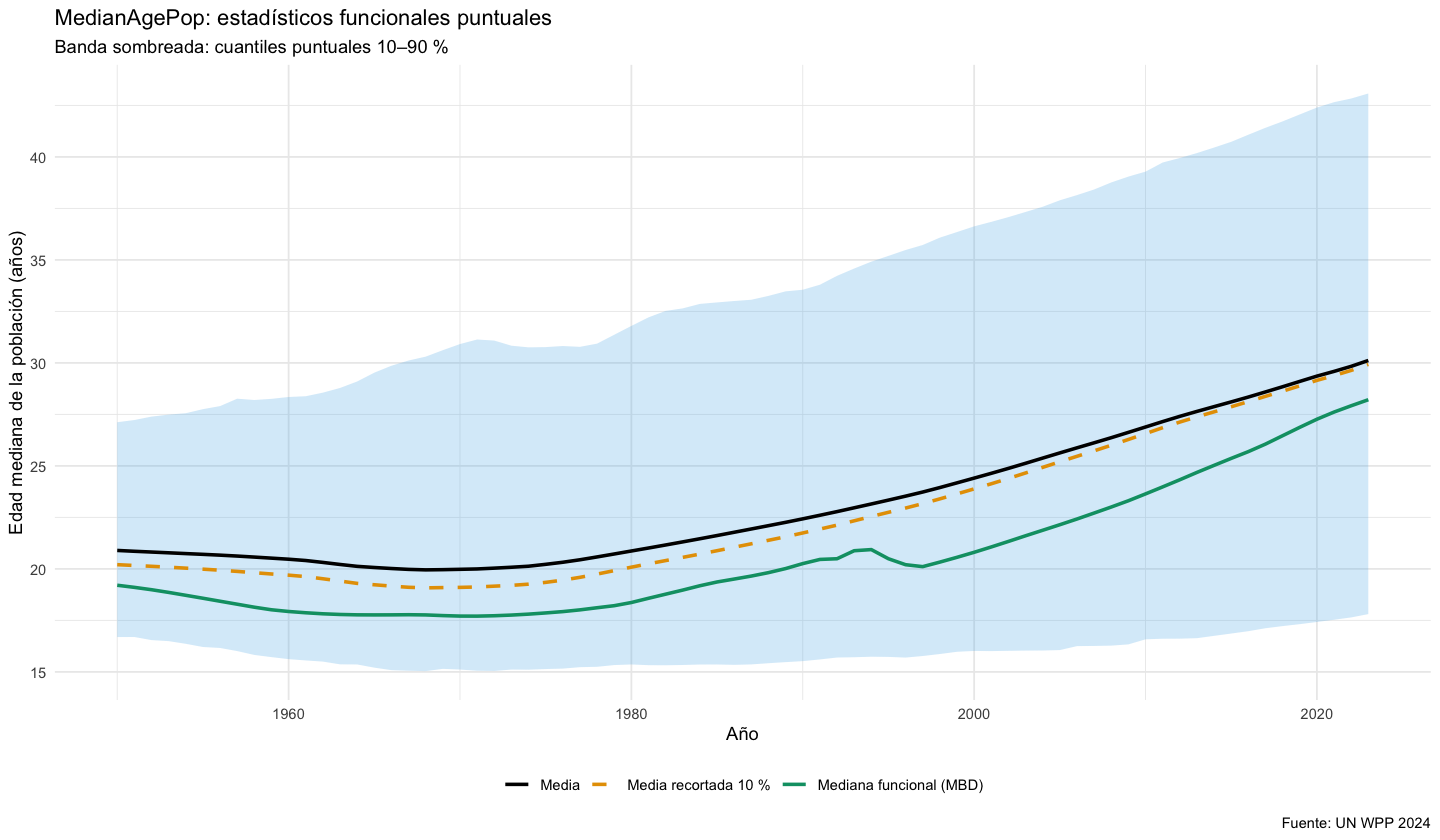

In [20]:
est <- estadisticos(M)
mediana_pais <- meta$Location[which.max(MBD(fData(ANIOS, M)))]
cat("Mediana funcional (MBD):", mediana_pais, "\n")
est |> filter(Time %in% c(1950, 1970, 1990, 2010, 2023)) |>
  select(Time, media, media_rec, mediana_MBD, q10, q90) |> mutate(across(-Time, ~ round(.x, 3))) |>
  as.data.frame() |> print(row.names = FALSE)
p <- fig_estadisticos(est, "MedianAgePop")
guardar_fig(p, "eda_MedianAgePop_estadisticos"); p


## MedianAgePop · 3. Dispersión entre países: $\hat v(t)$ y CV(t)


 Time   media       v     cv
 1950 20.8958 21.3126 0.2209
 1960 20.4701 27.1420 0.2545
 1970 19.9795 32.8029 0.2867
 1980 20.8689 36.4084 0.2891
 1990 22.4293 47.0104 0.3057
 2000 24.4070 60.5615 0.3188
 2010 26.8884 72.7224 0.3172
 2020 29.3586 86.2072 0.3163
 2023 30.1178 89.1522 0.3135
v máx: 89.1522 en 2023 | v mín: 21.3126 en 1950


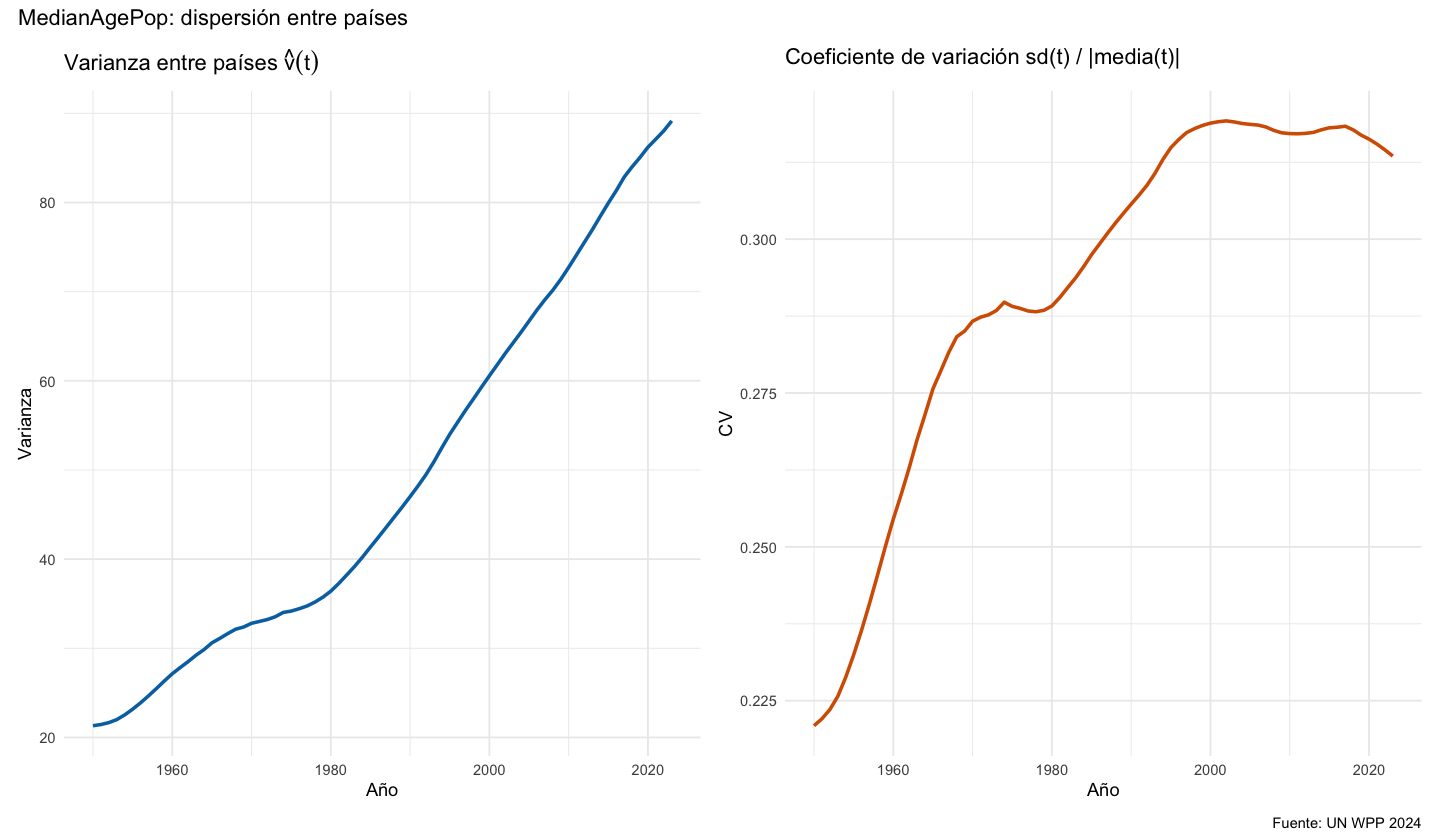

In [21]:
est |> filter(Time %in% c(1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023)) |>
  select(Time, media, v, cv) |> mutate(across(-Time, ~ round(.x, 4))) |>
  as.data.frame() |> print(row.names = FALSE)
cat(sprintf("v máx: %.4f en %d | v mín: %.4f en %d\n", max(est$v), est$Time[which.max(est$v)],
            min(est$v), est$Time[which.min(est$v)]))
p <- fig_varianza(est, "MedianAgePop")
guardar_fig(p, "eda_MedianAgePop_varianza", w = 11, h = 5); p


**Interpretación (MedianAgePop).** Es el indicador con la **divergencia más fuerte y sostenida**:
- $\hat v(t)$ crece de forma casi monótona, de 21.3 en 1950 a 89.2 en 2023 (4.2 veces). El máximo está al final del período.
- El CV sube de 0.22 a ~0.32 hasta el año 2000 y luego se estabiliza, así que la divergencia también es relativa, no solo un efecto de que el nivel medio suba.

El mecanismo es el desfase de la transición demográfica. Europa y Northern America envejecen desde 1970 (hasta ~40 años en 2023). Asia y América Latina se separan de África desde ~1975 y alcanzan la media global. África permanece cerca de 17–20 años, porque su fecundidad sigue siendo alta. Antes de 1970 la media baja levemente en casi todas las regiones (el baby boom y la caída de la mortalidad infantil rejuvenecen la población).

Como MedianAgePop resume el efecto acumulado de fecundidad, mortalidad y migración, su divergencia refleja que esos tres motores operan a ritmos distintos según la región. Por eso solo entra en el conjunto ampliado.


## MedianAgePop · 4. Atípicos: boxplot funcional y outliergram
El boxplot funcional detecta **atípicos de magnitud** (curvas que salen de las vallas) y el outliergram detecta **atípicos de forma** (curvas muy por debajo de la cota parabólica MBD–MEI). La tabla se guarda en `output/tables/outliers_MedianAgePop.csv`.


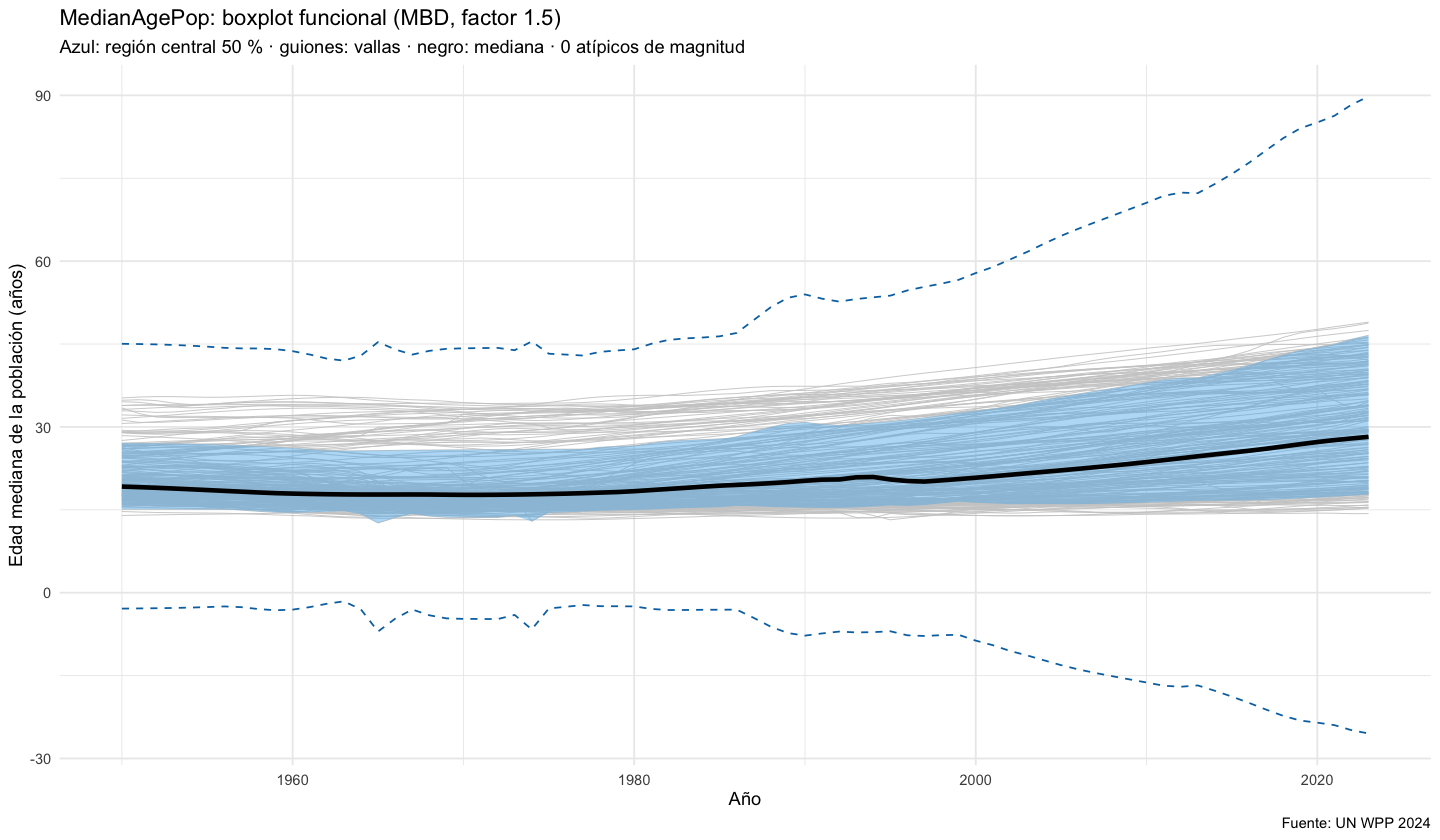

Atípicos de magnitud: 0 | de forma: 2 | en ambos: 0
    indicador  tipo ISO3_code    Location                          region
 MedianAgePop forma       MLI        Mali                          Africa
 MedianAgePop forma       LCA Saint Lucia Latin America and the Caribbean


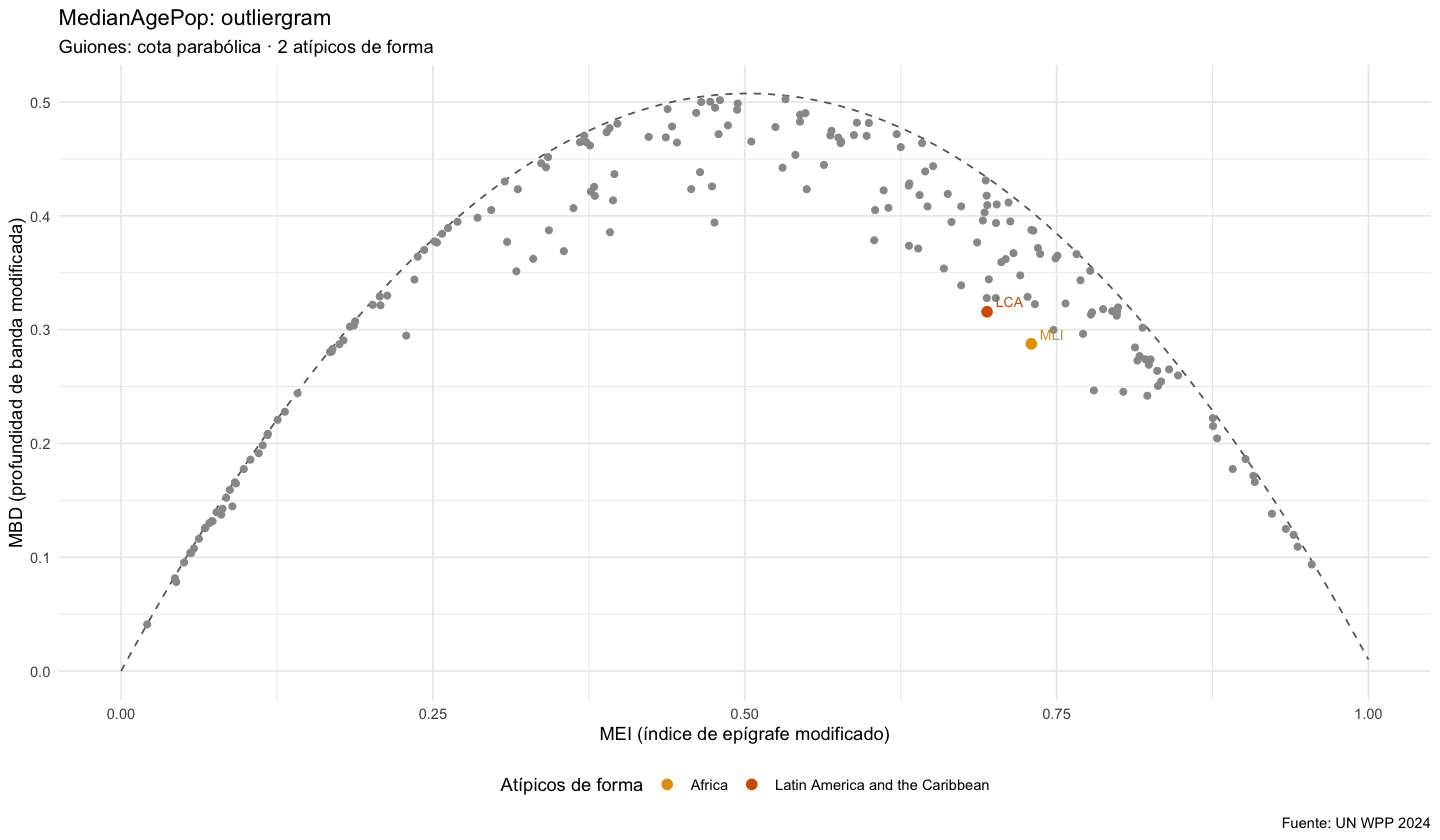

In [22]:
at <- analizar_atipicos(M)
p1 <- fig_fbplot(M, at, "MedianAgePop");      guardar_fig(p1, "eda_MedianAgePop_fbplot")
p2 <- fig_outliergram(M, at, "MedianAgePop"); guardar_fig(p2, "eda_MedianAgePop_outliergram")
print(p1); print(p2)

tab_at <- tabla_atipicos(at, "MedianAgePop")
guardar_tabla(tab_at, "outliers_MedianAgePop")
cat(sprintf("Atípicos de magnitud: %d | de forma: %d | en ambos: %d\n",
            length(at$id_mag), length(at$id_forma), length(intersect(at$id_mag, at$id_forma))))
print(as.data.frame(tab_at), row.names = FALSE)

resumen[["MedianAgePop"]] <- tibble(indicador = "MedianAgePop",
                              v_1950 = est$v[est$Time == 1950], v_2023 = est$v[est$Time == 2023],
                              n_atip_magnitud = length(at$id_mag), n_atip_forma = length(at$id_forma))


# Síntesis comparada

## 5. Varianza entre países de los cinco indicadores
Para comparar indicadores con unidades distintas, cada $\hat v_k(t)$ se divide por su máximo en 1950–2023: $\tilde v_k(t)=\hat v_k(t)/\max_s \hat v_k(s)$. Así se ve en qué años cada indicador alcanza su mayor dispersión y si esta crece o decrece.


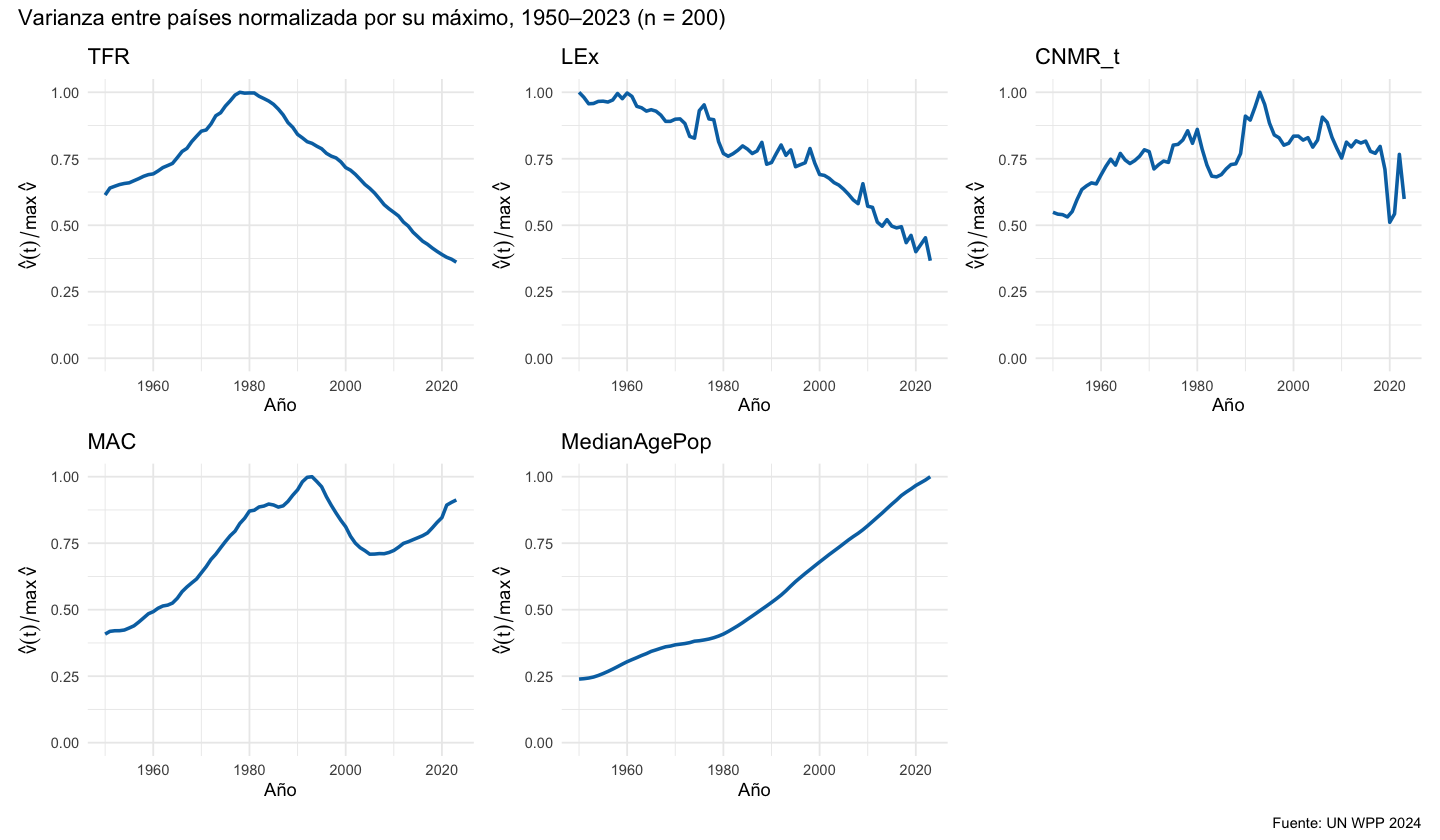

In [23]:
var_norm <- imap_dfr(mats, function(M, ind) {
  v <- apply(M, 2, var)
  tibble(indicador = ind, Time = ANIOS, v = v, v_norm = v / max(v))
})
stopifnot(all(abs(tapply(var_norm$v_norm, var_norm$indicador, max) - 1) < 1e-12))

paneles <- lapply(IND_EDA, function(ind) {
  ggplot(filter(var_norm, indicador == ind), aes(Time, v_norm)) +
    geom_line(linewidth = 1, colour = "#0072B2") +
    scale_y_continuous(limits = c(0, 1)) +
    labs(title = ind, x = "Año", y = expression(hat(v)(t) / max ~ hat(v))) +
    theme_minimal(base_size = 11)
})
p <- wrap_plots(paneles, ncol = 3) +
  plot_annotation(title = "Varianza entre países normalizada por su máximo, 1950–2023 (n = 200)",
                  caption = CAPTION, theme = theme_minimal(base_size = 11))
guardar_fig(p, "eda_panel_varianza", w = 12, h = 7); p


## 6. CNMR original frente a CNMR_t = asinh(CNMR)
En la escala original, unos pocos episodios extremos (Kuwait 1990: −710 ‰; Hong Kong y Macao 1964: ~+355 ‰) fijan la escala del eje y aplastan al resto de países cerca de cero. En ese caso la varianza entre países, la normalización de Chiou y el MFPCA quedarían dominados por un puñado de años y países. La transformación $\operatorname{asinh}$ comprime las colas de forma logarítmica, conserva el signo y deja casi intactos los valores pequeños ($\operatorname{asinh}(x)\approx x$ para $|x|<1$).


Varianza máxima entre países: CNMR = 3178.3 (año 1990) | CNMR_t = 6.08
Razón var máx / var mediana entre años: CNMR = 22.6 | CNMR_t = 1.30


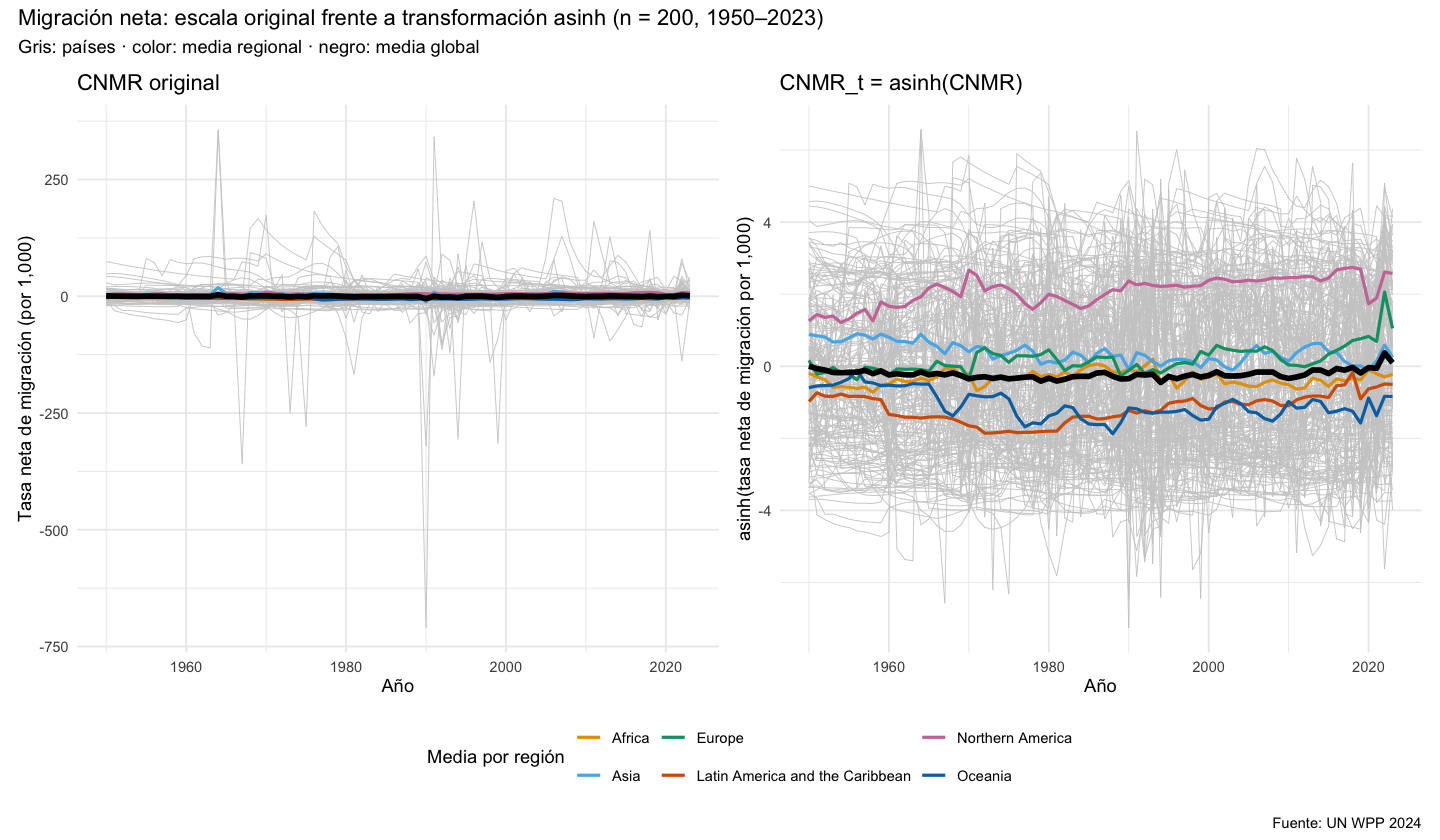

In [24]:
panel_paises <- readRDS(here::here("output/data/panel_paises.rds"))
M_cnmr <- panel_paises |>
  filter(!es_pequeno, Time >= HORIZONTE[1], Time <= HORIZONTE[2]) |>
  select(ISO3_code, Time, CNMR) |>
  pivot_wider(names_from = Time, values_from = CNMR) |>
  column_to_rownames("ISO3_code") |> as.matrix()
M_cnmr <- M_cnmr[meta$ISO3_code, as.character(ANIOS)]
stopifnot(!anyNA(M_cnmr), max(abs(asinh(M_cnmr) - mats$CNMR_t)) < 1e-12)

cat(sprintf("Varianza máxima entre países: CNMR = %.1f (año %d) | CNMR_t = %.2f\n",
            max(apply(M_cnmr, 2, var)), ANIOS[which.max(apply(M_cnmr, 2, var))], max(apply(mats$CNMR_t, 2, var))))
cat(sprintf("Razón var máx / var mediana entre años: CNMR = %.1f | CNMR_t = %.2f\n",
            max(apply(M_cnmr, 2, var)) / median(apply(M_cnmr, 2, var)),
            max(apply(mats$CNMR_t, 2, var)) / median(apply(mats$CNMR_t, 2, var))))

p1 <- fig_spaghetti(M_cnmr, "CNMR", ylab = "Tasa neta de migración (por 1,000)",
                    titulo = "CNMR original")
p2 <- fig_spaghetti(mats$CNMR_t, "CNMR_t", titulo = "CNMR_t = asinh(CNMR)")
p <- (p1 | p2) + plot_layout(guides = "collect") &
  theme(legend.position = "bottom", plot.caption = element_blank(), plot.subtitle = element_blank())
p <- p + plot_annotation(title = "Migración neta: escala original frente a transformación asinh (n = 200, 1950–2023)",
                         subtitle = "Gris: países · color: media regional · negro: media global",
                         caption = CAPTION,
                         theme = theme_minimal(base_size = 11) + theme(legend.position = "bottom"))
guardar_fig(p, "eda_CNMR_transformacion", w = 13, h = 6.5); p


## 7. Tabla resumen
Varianza entre países en 1950 y 2023, la razón $\hat v(2023)/\hat v(1950)$ (> 1: divergencia neta; < 1: convergencia neta) y el número de atípicos de magnitud (boxplot funcional) y de forma (outliergram). Se guarda en `output/tables/eda_resumen.csv` y `.tex`.


In [25]:
tabla_resumen <- bind_rows(resumen) |>
  mutate(razon_v = v_2023 / v_1950) |>
  select(indicador, v_1950, v_2023, razon_v, n_atip_magnitud, n_atip_forma) |>
  mutate(across(c(v_1950, v_2023, razon_v), ~ round(.x, 3)))
stopifnot(identical(tabla_resumen$indicador, IND_EDA))
guardar_tabla(tabla_resumen, "eda_resumen", tex = TRUE)
print(as.data.frame(tabla_resumen), row.names = FALSE)


    indicador  v_1950 v_2023 razon_v n_atip_magnitud n_atip_forma
          TFR   2.598  1.529   0.589               0           14
          LEx 136.918 50.196   0.367               4           17
       CNMR_t   3.336  3.640   1.091               0            1
          MAC   1.106  2.473   2.236               0            5
 MedianAgePop  21.313 89.152   4.183               0            2


## 8. Conclusiones de F2

**Convergencia y divergencia** ($\hat v(2023)/\hat v(1950)$, n = 200):

| Indicador | Razón | Patrón |
|---|---|---|
| LEx | 0.37 | Convergencia sostenida, absoluta y relativa; saltos breves por crisis de mortalidad. |
| TFR | 0.59 | Divergencia hasta 1978 y luego convergencia absoluta; el CV no baja, así que no hay convergencia relativa. |
| CNMR_t | 1.09 | Sin tendencia clara: sube hasta 1993, luego una meseta ruidosa y el choque COVID/Ucrania en 2020–2022. |
| MAC | 2.24 | Onda: divergencia, convergencia transitoria (1993–2006) y nueva divergencia por el aplazamiento de la maternidad. |
| MedianAgePop | 4.18 | Divergencia monótona y fuerte: el envejecimiento avanza a ritmos muy distintos. |

**Lectura para la Pregunta 6.** Los indicadores no se mueven al unísono. La mortalidad converge, la fecundidad diverge y luego converge, y la estructura por edad diverge. Además, en TFR, MAC y MedianAgePop las regiones se distinguen más por el **momento y la forma** de sus cambios (cuándo empieza la transición, curvas en U en MAC) que por su nivel en un año dado. Esto respalda el enfoque funcional: un corte transversal de 2023 no vería esa información.

**Atípicos.**
- **De magnitud:** solo aparecen en LEx (Camboya, Ruanda, Sudán del Sur y República Centroafricana: caídas por guerra o genocidio). Con el factor 1.5, las vallas son muy anchas en TFR, MAC y MedianAgePop.
- **De forma:**
  - **TFR (14):** monarquías del Golfo e Irán (caída tardía y muy rápida), Taiwán y Singapur (caída temprana y profunda), y África central (fecundidad que *sube* antes de bajar).
  - **LEx (17):** las ex-repúblicas soviéticas (Rusia, Ucrania, Bielorrusia y los países bálticos, con estancamiento o caída en los noventa), el Golfo y el Magreb (subida muy rápida) y Zimbabue (caída por VIH/sida).
  - **MAC (5) y MedianAgePop (2):** muy pocos.
  - **CNMR_t (1, Armenia):** casi todas las curvas se cruzan entre sí, así que el outliergram apenas discrimina.
- Estos países son candidatos a formar grupos pequeños o a quedar mal clasificados en F6. Hay que seguirlos de cerca.

**CNMR.** En la escala original, la varianza máxima entre países (1990) es 22.6 veces la varianza mediana entre años; con $\operatorname{asinh}$ la razón baja a 1.30. La transformación es necesaria para que unos pocos episodios no dominen la normalización ni el MFPCA. Aun así, CNMR_t sigue siendo la dimensión más ruidosa de un año a otro, así que en F3 conviene suavizarla (P-spline con GCV), como prevé el plan.

**Para F3–F5:**
- $\min_t \hat v_k(t)>0$ se cumple con holgura para los cinco indicadores (mínimos: TFR 1.53, LEx 50.2, CNMR_t 3.11, MAC 1.11, MedianAgePop 21.3), lo que es relevante para la normalización de Chiou.
- Las caídas de LEx por crisis y COVID-19 son de uno o pocos años; el FPCA las tratará como ruido de alta frecuencia.

**Nota técnica.** En esta fase se corrigió `guardar_fig()` en `00_configuracion.ipynb`: el PDF ahora usa `encoding = "WinAnsi.enc"`, para que la raya (–) no se sustituya por un guion.
